In [1]:
# @title
%pip install pandas numpy matplotlib seaborn

# Week 7: Hands-On ML Solution Data Visualizations

**Project:** FinMark Corporation  
**Course:** MO-IT162 Math for Machine Learning: Linear Algebra  
**Section:** A3101  
**Student:** James Lynelle Ongo


## Project Context

FinMark Corporation uses customer demographics, transaction records, and social media interaction data to understand customer behavior and market activity.

Milestone 1 focused on verifying, cleaning, exploring, and interpreting these datasets. This Week 7 activity builds on those results by using NumPy, Matplotlib, and Seaborn to explore meaningful variable combinations and test different visualization approaches.

The visualizations created in this notebook are exploratory. Multiple chart types and data combinations may be tested before selecting the most suitable visualizations for the final Milestone 2 analysis.


## Week 7 Objectives

This notebook aims to:

1. Load and confirm the finalized cleaned FinMark datasets used during Milestone 1.
2. Extend selected Milestone 1 findings using NumPy and additional numerical analysis.
3. Explore meaningful combinations of variables within and across the FinMark datasets.
4. Test different Matplotlib and Seaborn visualization methods for distributions, frequencies, comparisons, relationships, trends, and unusual observations.
5. Compare candidate visualizations based on readability, analytical value, and suitability for the FinMark business problem.
6. Identify which data combinations and visualization methods are most appropriate for the final Milestone 2 analysis.
7. Document important observations and considerations relevant to future machine learning activities.


## Scope and Constraints

### Included

The Week 7 analysis focuses on:

- the finalized cleaned customer demographics dataset;
- the finalized cleaned customer transactions dataset;
- the finalized cleaned social media interactions dataset;
- additional numerical analysis using NumPy;
- exploratory visualizations using Matplotlib and Seaborn;
- numerical distributions;
- categorical frequencies and comparisons;
- trends over time;
- relationships between variables;
- meaningful cross-dataset customer-level analysis;
- category imbalance and unusual observations when applicable; and
- comparison of different visualization options before final selection.

### Constraints

The following limitations and boundaries are applied:

- No new external datasets are introduced.
- Customer, transaction, and interaction identifiers are treated as identifiers rather than numerical analytical features.
- Cross-dataset analysis is limited to combinations that support a meaningful FinMark analytical question.
- Transaction-level and social-interaction-level records are not directly merged because this may create many-to-many duplication.
- Customer-level aggregation is performed before cross-dataset relationship analysis when required.
- Visual relationships and correlations are interpreted descriptively and do not establish causation.
- Predictive model training and model evaluation are outside the scope of this Week 7 activity.


## Data Sources and Analytical Lineage

This notebook uses the finalized cleaned datasets produced during the Week 3 preprocessing activity and used in Milestone 1.

The project data flow is:

**Raw FinMark Data**  
↓  
**Week 3 Data Preprocessing**  
↓  
**Final Cleaned Datasets**  
↓  
**Milestone 1 Exploratory Data Analysis**  
↓  
**Week 7 Visualization Exploration**  
↓  
**Milestone 2 Visualization Analysis**

The following cleaned datasets are used:

| Dataset | Main Purpose |
|---|---|
| Customer Demographics | Customer age, gender, income level, location, and signup information |
| Customer Transactions | Purchase activity, transaction amount, product category, payment method, and transaction dates |
| Social Media Interactions | Platform activity, interaction type, sentiment, and interaction dates |

No additional cleaning is performed unless an issue affecting the visualization analysis is discovered.


## Notebook Setup and Data Verification

The required Python libraries are imported, the finalized cleaned FinMark datasets are loaded from the project repository, and their basic structure is verified before visualization.

This verification confirms dataset dimensions, missing values, exact duplicates, and available variables. It is not a second cleaning stage.


In [2]:
# @title Import Required Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats


In [3]:
# @title Load Finalized Cleaned FinMark Datasets
GITHUB_OWNER = "Baelfyre"
GITHUB_REPO = "A3101-ml-linear-algebra-project-Team-3"
GITHUB_BRANCH = "main"
WEEK3_REPO_DIR = "Week3_Preprocessing_Submission"

GITHUB_RAW_BASE = (
    f"https://raw.githubusercontent.com/"
    f"{GITHUB_OWNER}/{GITHUB_REPO}/{GITHUB_BRANCH}"
)

WEEK3_SOURCE_URL = (
    f"{GITHUB_RAW_BASE}/{WEEK3_REPO_DIR}"
)

demographics = pd.read_csv(
    f"{WEEK3_SOURCE_URL}/customer_demographics_cleaned.csv"
)

transactions = pd.read_csv(
    f"{WEEK3_SOURCE_URL}/customer_transactions_cleaned.csv"
)

social = pd.read_csv(
    f"{WEEK3_SOURCE_URL}/social_media_interactions_cleaned.csv"
)


In [4]:
# @title Verify Loaded FinMark Datasets

datasets = {
    "Customer Demographics": demographics,
    "Customer Transactions": transactions,
    "Social Media Interactions": social
}

verification_rows = []

for name, df in datasets.items():
    verification_rows.append({
        "Dataset": name,
        "Rows": df.shape[0],
        "Columns": df.shape[1],
        "Missing Values": int(df.isna().sum().sum()),
        "Exact Duplicates": int(df.duplicated().sum())
    })

verification_summary = pd.DataFrame(verification_rows)
display(verification_summary)

column_summary = pd.DataFrame({
    "Dataset": list(datasets.keys()),
    "Variables": [
        ", ".join(df.columns)
        for df in datasets.values()
    ]
})

display(column_summary)


,Dataset,Rows,Columns,Missing Values,Exact Duplicates
0,Customer Demographics,2378,6,0,0
1,Customer Transactions,2420,6,0,0
2,Social Media Interactions,2411,6,0,0


,Dataset,Variables
0,Customer Demographics,"customer_id, age, gender, location, income_lev..."
1,Customer Transactions,"customer_id, transaction_id, transaction_date,..."
2,Social Media Interactions,"customer_id, interaction_id, interaction_date,..."


## Exploratory Visualization Methodology

The Week 7 analysis follows a question-first approach.

Rather than selecting a chart first and then finding data to fit it, each visualization begins with an analytical question relevant to FinMark.

The exploration follows this process:

**Analytical Question**  
↓  
**Relevant Dataset or Dataset Combination**  
↓  
**Relevant Variables**  
↓  
**Required Numerical Analysis or Aggregation**  
↓  
**Candidate Visualization Methods**  
↓  
**Visual Comparison and Interpretation**  
↓  
**Decision to Keep, Refine, or Exclude**

Three levels of analysis are explored:

### 1. Single-Dataset Analysis

Each dataset is first examined independently to understand distributions, frequencies, comparisons, and trends.

### 2. Two-Dataset Analysis

Datasets are combined only when the relationship supports a meaningful FinMark question, such as:

- demographics and transaction behavior;
- demographics and social media engagement; or
- social media engagement and transaction behavior.

### 3. Integrated Customer-Level Analysis

Selected variables from all three datasets may be combined at the customer level to explore broader relationships relevant to future machine learning work.

Not every possible variable combination will be analyzed. Priority is given to combinations that are meaningful to FinMark's need to understand customer behavior and market activity.


## Exploratory Visualization Standards

The visualizations in this notebook are preliminary candidates used to determine which charts are most suitable for Milestone 2.

The exploratory worksheet intentionally keeps charts that may later be excluded. This preserves the analytical trail showing what was tested, what the data revealed, and why a visualization was kept, refined, or dropped.

In addition to readable titles, axes, and formatting, each candidate is reviewed against the FinMark Visualization Standard:

- **Clarity:** one main analytical question per chart;
- **Relevance:** the chart must contribute to the FinMark problem statement;
- **Accuracy:** use appropriate scales, units, denominators, aggregation levels, and statistical measures;
- **Consistency:** use stable terminology, category ordering, labels, and formatting;
- **Accessibility:** do not rely on color alone and keep labels readable;
- **Organization:** group related visuals by analytical purpose;
- **Hierarchy:** prioritize decision-relevant findings over descriptive background;
- **Interactivity:** reserve interactive controls for the final dashboard when they improve investigation;
- **Context:** show the population, period, units, and limitations needed to interpret the chart; and
- **Aesthetics:** keep presentation clean without unnecessary decoration.

Exploratory charts remain labeled with **"Exploratory:"** where applicable. The final Milestone 2 notebook will retain only the strongest visualization set rather than maximizing chart count.


In [5]:
# @title Visualization Theme and Formatting Standards

sns.set_theme(
    style="whitegrid",
    context="notebook",
    palette="deep"
)


# Shared theme colors for single-series charts
primary_color = sns.color_palette("deep")[0]
secondary_color = sns.color_palette("deep")[1]

plt.rcParams.update({
    "figure.figsize": (8, 5),
    "figure.dpi": 100,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "figure.titlesize": 15
})

# Shared category orders used throughout the notebook
income_order = ["Low", "Medium", "High"]

sentiment_order = [
    "Very Negative",
    "Negative",
    "Neutral",
    "Positive",
    "Very Positive"
]

sentiment_index_map = {
    "Very Negative": -2,
    "Negative": -1,
    "Neutral": 0,
    "Positive": 1,
    "Very Positive": 2
}


In [6]:
# @title Reusable Visualization Helper

def add_count_labels(ax, total):
    """Display count and percentage labels above categorical bars."""

    for container in ax.containers:
        for bar in container:
            count = bar.get_height()

            if count > 0:
                percentage = (count / total) * 100

                ax.annotate(
                    f"{int(count):,}\n({percentage:.2f}%)",
                    xy=(
                        bar.get_x() + bar.get_width() / 2,
                        count
                    ),
                    xytext=(0, 4),
                    textcoords="offset points",
                    ha="center",
                    va="bottom",
                    fontsize=9
                )


# Part I: Single-Dataset Exploration

The first stage of visualization exploration examines each FinMark dataset independently.

This allows the structure, distributions, category patterns, numerical spread, and time-based behavior of each dataset to be understood before exploring relationships across multiple data sources.

For each analytical question, numerical evidence is reviewed first when applicable. Different visualization approaches are then tested to determine which representation provides the clearest analytical value.


## 1. Customer Demographics

The customer demographics dataset contains information about individual FinMark customers, including age, gender, income level, location, and signup date.

The exploratory analysis focuses on variables that can provide meaningful information about customer composition and demographic patterns. The `customer_id` field is retained only as an identifier and is not treated as a numerical analytical feature.

The `location` variable is also not prioritized for direct visualization because the cleaned dataset contains a very large number of unique locations. Plotting all locations would produce a highly fragmented chart with limited analytical value.

### Exploration Questions

| Analytical Question | Variable(s) | Candidate Visualization |
|---|---|---|
| How are customer ages distributed? | `age` | Histogram, Box Plot |
| Are gender categories balanced? | `gender` | Count Plot, Bar Chart |
| Are income-level categories balanced? | `income_level` | Count Plot, Bar Chart |
| How did recorded customer signups change over time? | `signup_date` | Line Plot |


### 1.1 Customer Age Numerical Analysis

Customer age is a numerical variable. Before testing visualization options, NumPy is used to summarize its central tendency and spread.

The numerical summary provides a reference that can later be compared with the visual distribution.


In [7]:
# @title Customer Age Numerical Summary

age_values = demographics["age"].to_numpy()

age_summary = pd.DataFrame({
    "Statistic": [
        "Count",
        "Mean",
        "Median",
        "Standard Deviation",
        "Variance",
        "Minimum",
        "Maximum"
    ],
    "Value": [
        len(age_values),
        np.mean(age_values),
        np.median(age_values),
        np.std(age_values, ddof=1),
        np.var(age_values, ddof=1),
        np.min(age_values),
        np.max(age_values)
    ]
})

age_summary["Value"] = age_summary["Value"].map(
    lambda x: f"{x:,.2f}"
)

display(age_summary)


,Statistic,Value
0,Count,"2,378.00"
1,Mean,44.73
2,Median,45.00
3,Standard Deviation,15.44
4,Variance,238.33
5,Minimum,18.00
6,Maximum,70.00


### 1.2 Customer Age Visualization Options

Two visualization methods are tested for the `age` variable.

**Histogram:** Shows how customer ages are distributed across age ranges and makes the overall shape and concentration of the data easier to observe.

**Box Plot:** Provides a compact representation of the median, quartiles, overall spread, and potential outliers.

Both charts represent the same numerical variable but answer different analytical questions. They are compared to determine whether one or both should be retained for the final Milestone 2 analysis.


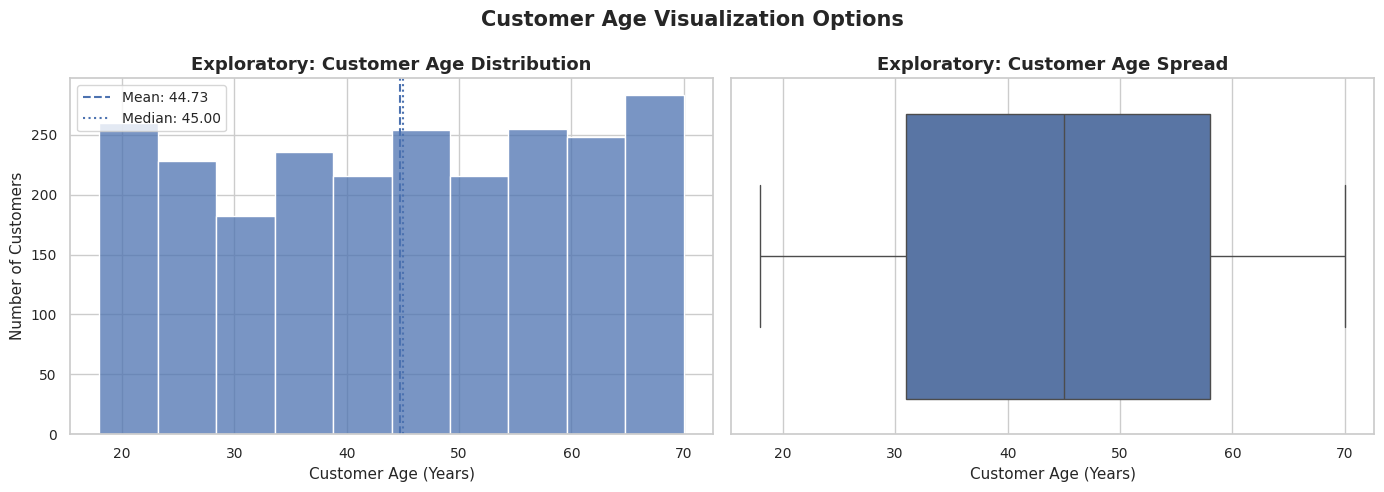

In [8]:
# @title Exploratory Customer Age Visualizations

age_mean = np.mean(age_values)
age_median = np.median(age_values)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram
sns.histplot(
    data=demographics,
    x="age",
    bins=10,
    color=primary_color,
    ax=axes[0]
)

axes[0].axvline(
    age_mean,
    linestyle="--",
    linewidth=1.5,
    label=f"Mean: {age_mean:.2f}"
)

axes[0].axvline(
    age_median,
    linestyle=":",
    linewidth=1.5,
    label=f"Median: {age_median:.2f}"
)

axes[0].set_title("Exploratory: Customer Age Distribution")
axes[0].set_xlabel("Customer Age (Years)")
axes[0].set_ylabel("Number of Customers")
axes[0].legend()

# Box plot
sns.boxplot(
    data=demographics,
    x="age",
    ax=axes[1]
)

axes[1].set_title("Exploratory: Customer Age Spread")
axes[1].set_xlabel("Customer Age (Years)")
axes[1].set_ylabel("")

fig.suptitle(
    "Customer Age Visualization Options",
    fontweight="bold"
)

plt.tight_layout()
plt.show()


#### Exploratory Review

The histogram and box plot were useful for understanding the customer-age distribution during exploration.

**Visualization Decision:** **SUPPORTING / DROP FROM FINAL.** The histogram may remain as descriptive context, but age distribution is not a core Milestone 2 business finding. The box plot is not retained in the final visualization set because it adds little decision value beyond the numerical summary.


### 1.3 Customer Composition Visualization Options

The `gender` and `income_level` variables are categorical and are explored to determine whether FinMark's cleaned customer demographic data contains dominant or imbalanced categories.

Count plots are used because they allow the number of customers in each category to be compared directly. Count and percentage labels are also displayed to make small differences easier to evaluate.


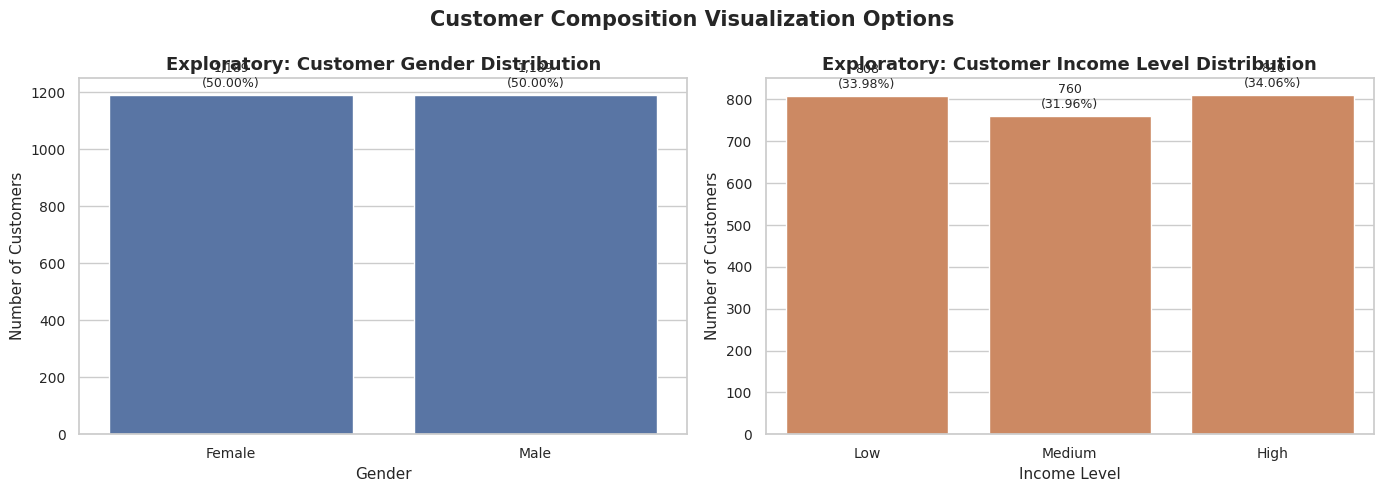

In [9]:
# @title Exploratory Customer Composition Visualizations

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gender distribution
sns.countplot(
    data=demographics,
    x="gender",
    color=primary_color,
    ax=axes[0]
)

axes[0].set_title("Exploratory: Customer Gender Distribution")
axes[0].set_xlabel("Gender")
axes[0].set_ylabel("Number of Customers")

add_count_labels(
    axes[0],
    len(demographics)
)

# Income-level distribution
sns.countplot(
    data=demographics,
    x="income_level",
    order=income_order,
    color=secondary_color,
    ax=axes[1]
)

axes[1].set_title("Exploratory: Customer Income Level Distribution")
axes[1].set_xlabel("Income Level")
axes[1].set_ylabel("Number of Customers")

add_count_labels(
    axes[1],
    len(demographics)
)

fig.suptitle(
    "Customer Composition Visualization Options",
    fontweight="bold"
)

plt.tight_layout()
plt.show()


#### Exploratory Review

Gender and income-level count plots confirm that the cleaned demographic categories are broadly balanced.

**Visualization Decision:** **DROP FROM FINAL.** These plots are useful for dataset understanding but do not directly solve the FinMark market-trend or customer-behavior questions. Gender is reconsidered later through product-category participation rather than simple frequency.


In [10]:
# @title Prepare Monthly Signup Activity

demographics["signup_date"] = pd.to_datetime(
    demographics["signup_date"]
)

monthly_signups = (
    demographics
    .set_index("signup_date")
    .resample("ME")
    .size()
    .reset_index(name="signup_count")
)

display(monthly_signups.head())


,signup_date,signup_count
0,2019-07-31,32
1,2019-08-31,39
2,2019-09-30,37
3,2019-10-31,39
4,2019-11-30,39


### 1.4 Customer Signup Trend

Customer signup dates are explored as a time-based variable to determine whether the number of recorded customer signups shows visible increases, decreases, or recurring patterns over the available observation period.

A line chart is tested because time order is important when evaluating changes in activity.


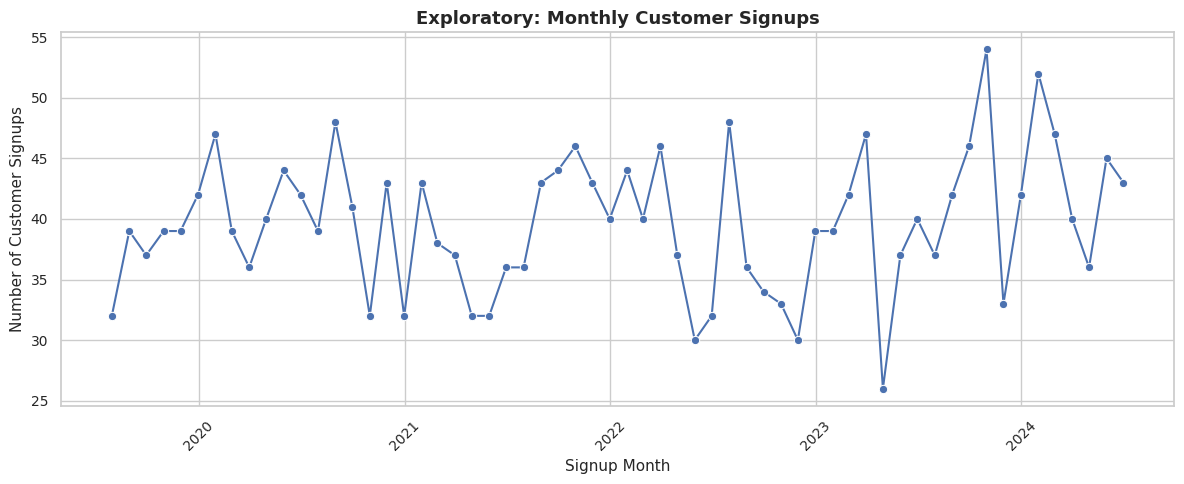

In [11]:
# @title Exploratory Monthly Customer Signup Trend

plt.figure(figsize=(12, 5))

sns.lineplot(
    data=monthly_signups,
    x="signup_date",
    y="signup_count",
    marker="o"
)

plt.title("Exploratory: Monthly Customer Signups")
plt.xlabel("Signup Month")
plt.ylabel("Number of Customer Signups")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


#### Exploratory Review

The signup trend is useful as descriptive background, but later logical checks show that some transaction dates precede the corresponding recorded signup dates.

**Visualization Decision:** **DROP FROM FINAL PRIMARY SET.** Keep the signup trend as exploratory context, but do not derive tenure or post-signup purchasing conclusions from it unless the date inconsistency is resolved.


## 2. Customer Transactions

The customer transactions dataset contains FinMark purchase records, including transaction amount, product category, payment method, and transaction date.

This section explores the distribution of transaction values, category frequencies, differences in transaction amounts across groups, and changes in transaction activity over time.

The `customer_id` and `transaction_id` fields are treated as identifiers and are not analyzed as numerical features.

### Exploration Questions

| Analytical Question | Variable(s) | Candidate Visualization |
|---|---|---|
| How are transaction amounts distributed? | `amount` | Histogram, Box Plot |
| Which product categories occur most frequently? | `product_category` | Count Plot, Bar Chart |
| Which payment methods are used most frequently? | `payment_method` | Count Plot, Bar Chart |
| Do transaction amounts differ across product categories? | `product_category`, `amount` | Box Plot, Median Bar Chart |
| Do transaction amounts differ across payment methods? | `payment_method`, `amount` | Box Plot, Median Bar Chart |
| How does transaction activity change over time? | `transaction_date` | Line Plot |


### 2.1 Transaction Amount Numerical Analysis

Transaction amount is a numerical variable representing the recorded value of each transaction.

Before testing visualization options, NumPy is used to summarize its central tendency and numerical spread. These values provide a reference for interpreting the distribution shown by the exploratory charts.


In [12]:
# @title Transaction Amount Numerical Summary

amount_values = transactions["amount"].to_numpy()

amount_summary = pd.DataFrame({
    "Statistic": [
        "Count",
        "Mean",
        "Median",
        "Standard Deviation",
        "Variance",
        "Minimum",
        "Maximum"
    ],
    "Value": [
        len(amount_values),
        np.mean(amount_values),
        np.median(amount_values),
        np.std(amount_values, ddof=1),
        np.var(amount_values, ddof=1),
        np.min(amount_values),
        np.max(amount_values)
    ]
})

amount_summary["Value"] = amount_summary["Value"].map(
    lambda x: f"{x:,.2f}"
)

display(amount_summary)


,Statistic,Value
0,Count,"2,420.00"
1,Mean,495.25
2,Median,502.12
3,Standard Deviation,295.71
4,Variance,"87,444.74"
5,Minimum,0.00
6,Maximum,999.86


### 2.2 Transaction Amount Visualization Options

Two complementary visualizations are tested for transaction amount.

**Histogram:** Shows how transaction values are distributed across different monetary ranges and helps identify concentration or uneven distribution.

**Box Plot:** Summarizes the median, quartiles, spread, and potential statistical outliers.

The two charts are compared because the histogram provides more information about distribution shape, while the box plot provides a compact summary of numerical spread.


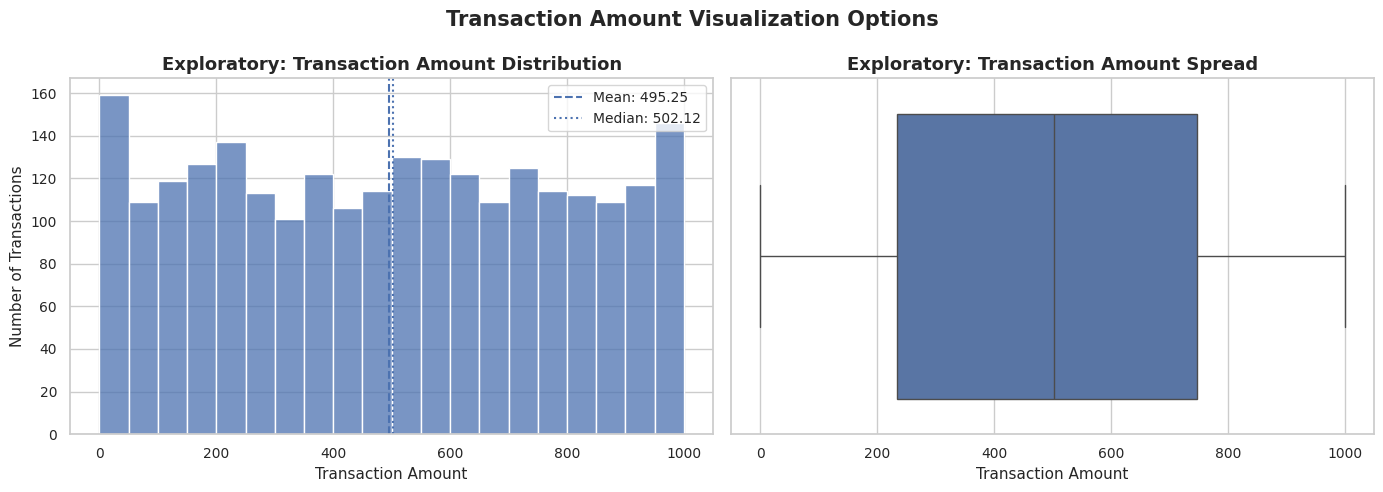

In [13]:
# @title Exploratory Transaction Amount Visualizations

amount_mean = np.mean(amount_values)
amount_median = np.median(amount_values)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram
sns.histplot(
    data=transactions,
    x="amount",
    bins=20,
    color=primary_color,
    ax=axes[0]
)

axes[0].axvline(
    amount_mean,
    linestyle="--",
    linewidth=1.5,
    label=f"Mean: {amount_mean:,.2f}"
)

axes[0].axvline(
    amount_median,
    linestyle=":",
    linewidth=1.5,
    label=f"Median: {amount_median:,.2f}"
)

axes[0].set_title("Exploratory: Transaction Amount Distribution")
axes[0].set_xlabel("Transaction Amount")
axes[0].set_ylabel("Number of Transactions")
axes[0].legend()

# Box plot
sns.boxplot(
    data=transactions,
    x="amount",
    ax=axes[1]
)

axes[1].set_title("Exploratory: Transaction Amount Spread")
axes[1].set_xlabel("Transaction Amount")
axes[1].set_ylabel("")

fig.suptitle(
    "Transaction Amount Visualization Options",
    fontweight="bold"
)

plt.tight_layout()
plt.show()


#### Exploratory Review

The transaction amount histogram and box plot both describe spread, but the histogram communicates the distribution more directly.

**Visualization Decision:** **KEEP / REFINE HISTOGRAM; DROP BOX PLOT.** Milestone 2 retains the histogram as the primary transaction-value distribution chart.


### 2.3 Transaction Composition Visualization Options

The `product_category` and `payment_method` variables are categorical.

Their frequency distributions are explored to determine whether particular product categories or payment methods dominate the cleaned transaction dataset.

Count plots with count and percentage labels are used because they allow category differences to be compared directly.


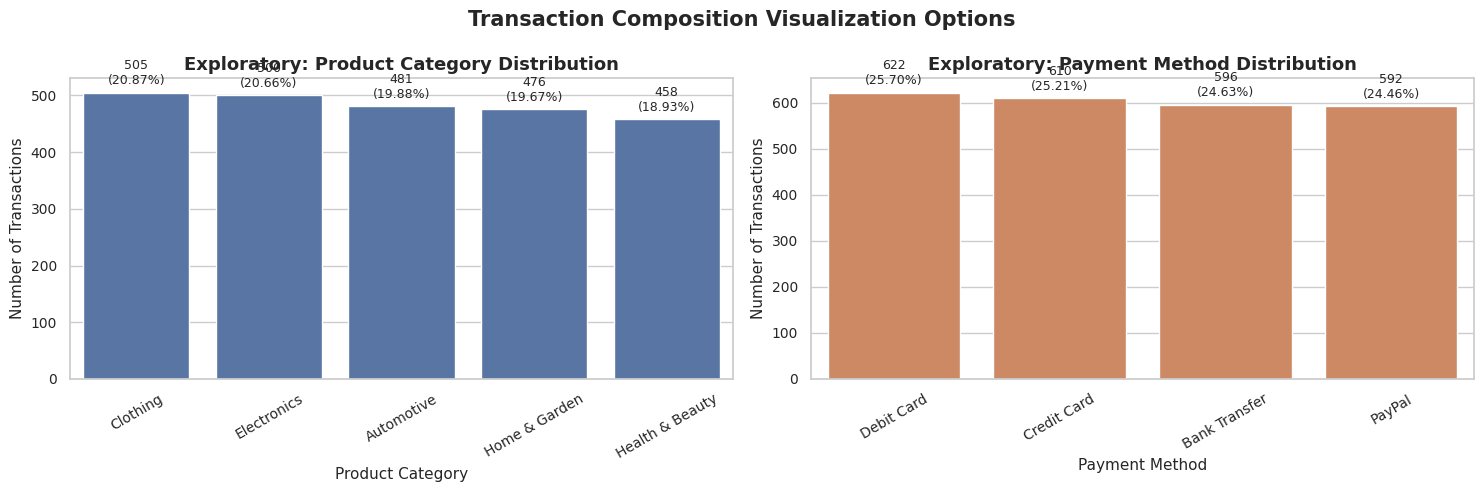

In [14]:
# @title Exploratory Transaction Composition Visualizations

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Product categories
product_order = (
    transactions["product_category"]
    .value_counts()
    .index
)

sns.countplot(
    data=transactions,
    x="product_category",
    order=product_order,
    color=primary_color,
    ax=axes[0]
)

axes[0].set_title("Exploratory: Product Category Distribution")
axes[0].set_xlabel("Product Category")
axes[0].set_ylabel("Number of Transactions")
axes[0].tick_params(axis="x", rotation=30)

add_count_labels(
    axes[0],
    len(transactions)
)

# Payment methods
payment_order = (
    transactions["payment_method"]
    .value_counts()
    .index
)

sns.countplot(
    data=transactions,
    x="payment_method",
    order=payment_order,
    color=secondary_color,
    ax=axes[1]
)

axes[1].set_title("Exploratory: Payment Method Distribution")
axes[1].set_xlabel("Payment Method")
axes[1].set_ylabel("Number of Transactions")
axes[1].tick_params(axis="x", rotation=30)

add_count_labels(
    axes[1],
    len(transactions)
)

fig.suptitle(
    "Transaction Composition Visualization Options",
    fontweight="bold"
)

plt.tight_layout()
plt.show()


#### Exploratory Review

Product-category and payment-method counts were useful for establishing whether activity is concentrated.

**Visualization Decision:** **REFINE PRODUCT CATEGORY; DROP PAYMENT METHOD.** Product category is carried forward using transaction count together with total transaction value. Payment-method frequency is not retained because the categories are comparatively balanced and provide limited decision value.


### 2.4 Transaction Amount by Product Category

The previous visualization compares how often each product category occurs. Frequency alone does not show whether transaction values differ between categories.

This analysis combines `product_category` and `amount` to examine whether the distribution and typical value of transactions vary across product categories.

Two visualization approaches are tested:

**Box Plot:** Shows the complete distribution, median, spread, overlap, and potential unusual observations for each category.

**Median Bar Chart:** Provides a simpler comparison of the typical transaction amount across categories.


In [15]:
# @title Product Category Transaction Amount Summary

product_amount_summary = (
    transactions
    .groupby("product_category")["amount"]
    .agg(
        transaction_count="count",
        mean_amount="mean",
        median_amount="median",
        std_amount="std"
    )
    .sort_values("median_amount", ascending=False)
    .reset_index()
)

display(
    product_amount_summary.style.format({
        "mean_amount": "{:,.2f}",
        "median_amount": "{:,.2f}",
        "std_amount": "{:,.2f}"
    })
)


,product_category,transaction_count,mean_amount,median_amount,std_amount
0,Automotive,481,502.35,517.45,289.01
1,Home & Garden,476,517.44,517.32,294.33
2,Electronics,500,486.62,505.80,286.02
3,Clothing,505,493.73,496.26,303.09
4,Health & Beauty,458,475.83,463.32,305.66


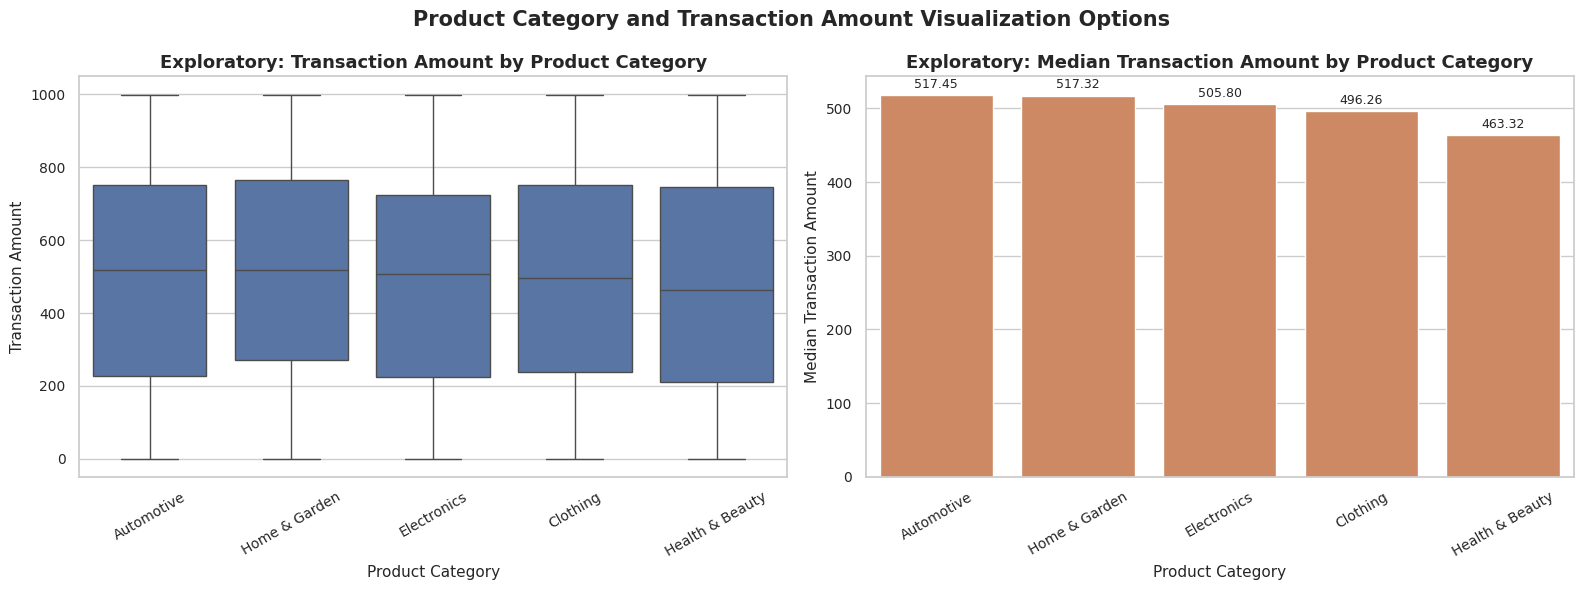

In [16]:
# @title Exploratory Product Category and Transaction Amount Visualizations

category_order = product_amount_summary["product_category"].tolist()

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Full distribution
sns.boxplot(
    data=transactions,
    x="product_category",
    y="amount",
    order=category_order,
    ax=axes[0]
)

axes[0].set_title(
    "Exploratory: Transaction Amount by Product Category"
)
axes[0].set_xlabel("Product Category")
axes[0].set_ylabel("Transaction Amount")
axes[0].tick_params(axis="x", rotation=30)

# Median comparison
sns.barplot(
    data=product_amount_summary,
    x="product_category",
    y="median_amount",
    order=category_order,
    color=secondary_color,
    ax=axes[1]
)

axes[1].set_title(
    "Exploratory: Median Transaction Amount by Product Category"
)
axes[1].set_xlabel("Product Category")
axes[1].set_ylabel("Median Transaction Amount")
axes[1].tick_params(axis="x", rotation=30)

for container in axes[1].containers:
    axes[1].bar_label(
        container,
        fmt="%.2f",
        padding=3,
        fontsize=9
    )

fig.suptitle(
    "Product Category and Transaction Amount Visualization Options",
    fontweight="bold"
)

plt.tight_layout()
plt.show()


#### Exploratory Review

The category amount plots show considerable overlap among categories.

**Visualization Decision:** **DROP AS FINAL CHART.** Instead of emphasizing overlapping amount distributions, Milestone 2 summarizes product-category performance using transaction count and total transaction value, with average and median amount retained in the supporting table.


### 2.5 Transaction Amount by Payment Method

This analysis explores whether transaction values differ across payment methods.

The objective is not to assume that payment method affects transaction value, but to determine whether the cleaned data shows meaningful descriptive differences between the groups.


In [17]:
# @title Payment Method Transaction Amount Summary

payment_amount_summary = (
    transactions
    .groupby("payment_method")["amount"]
    .agg(
        transaction_count="count",
        mean_amount="mean",
        median_amount="median",
        std_amount="std"
    )
    .sort_values("median_amount", ascending=False)
    .reset_index()
)

display(
    payment_amount_summary.style.format({
        "mean_amount": "{:,.2f}",
        "median_amount": "{:,.2f}",
        "std_amount": "{:,.2f}"
    })
)


,payment_method,transaction_count,mean_amount,median_amount,std_amount
0,PayPal,592,501.76,516.22,289.43
1,Debit Card,622,502.15,509.67,299.73
2,Credit Card,610,494.20,508.53,293.70
3,Bank Transfer,596,482.65,478.97,300.01


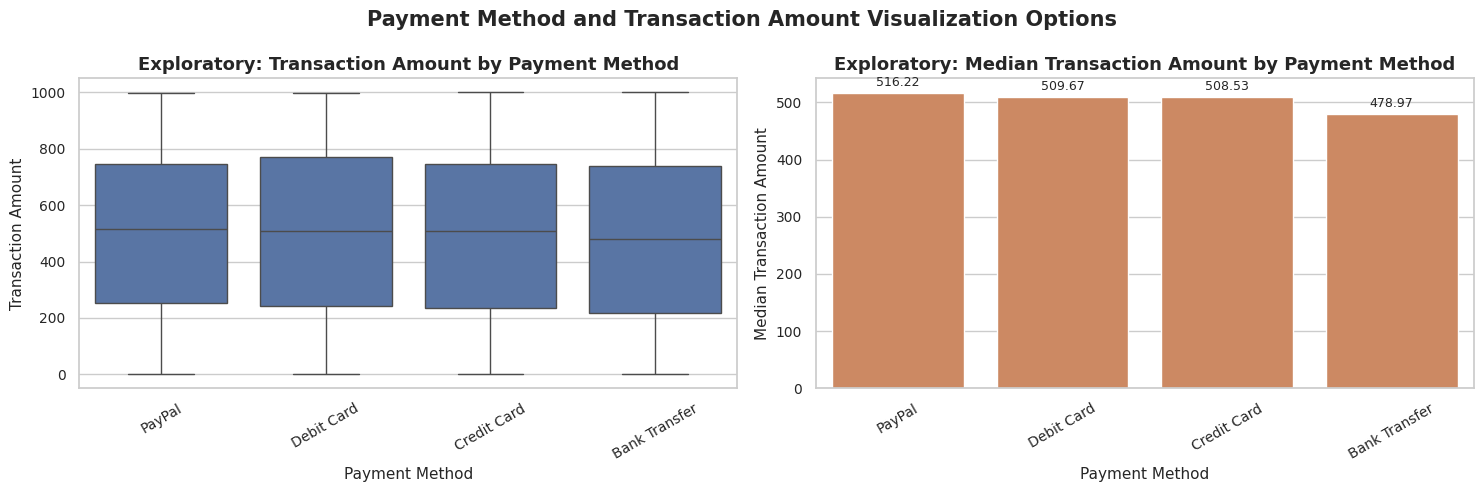

In [18]:
# @title Exploratory Payment Method and Transaction Amount Visualizations

payment_amount_order = (
    payment_amount_summary["payment_method"].tolist()
)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.boxplot(
    data=transactions,
    x="payment_method",
    y="amount",
    order=payment_amount_order,
    ax=axes[0]
)

axes[0].set_title(
    "Exploratory: Transaction Amount by Payment Method"
)
axes[0].set_xlabel("Payment Method")
axes[0].set_ylabel("Transaction Amount")
axes[0].tick_params(axis="x", rotation=30)

sns.barplot(
    data=payment_amount_summary,
    x="payment_method",
    y="median_amount",
    order=payment_amount_order,
    color=secondary_color,
    ax=axes[1]
)

axes[1].set_title(
    "Exploratory: Median Transaction Amount by Payment Method"
)
axes[1].set_xlabel("Payment Method")
axes[1].set_ylabel("Median Transaction Amount")
axes[1].tick_params(axis="x", rotation=30)

for container in axes[1].containers:
    axes[1].bar_label(
        container,
        fmt="%.2f",
        padding=3,
        fontsize=9
    )

fig.suptitle(
    "Payment Method and Transaction Amount Visualization Options",
    fontweight="bold"
)

plt.tight_layout()
plt.show()


#### Exploratory Review

Transaction-value distributions overlap strongly across payment methods.

**Visualization Decision:** **DROP FROM FINAL.** The relationship does not provide enough differentiation to justify dashboard space.


### 2.6 Monthly Transaction Activity

Transaction dates are aggregated by month to examine how recorded transaction activity changes over time.

A line chart is tested because the chronological order of the observations is important when evaluating increases, decreases, and fluctuations.

The visualization is descriptive. Visible peaks or declines should not automatically be interpreted as recurring seasonality.


In [19]:
# @title Prepare Monthly Transaction Activity

transactions["transaction_date"] = pd.to_datetime(
    transactions["transaction_date"]
)

monthly_transactions = (
    transactions
    .set_index("transaction_date")
    .resample("ME")
    .size()
    .reset_index(name="transaction_count")
)

display(monthly_transactions.head())


,transaction_date,transaction_count
0,2022-07-31,103
1,2022-08-31,87
2,2022-09-30,93
3,2022-10-31,94
4,2022-11-30,103


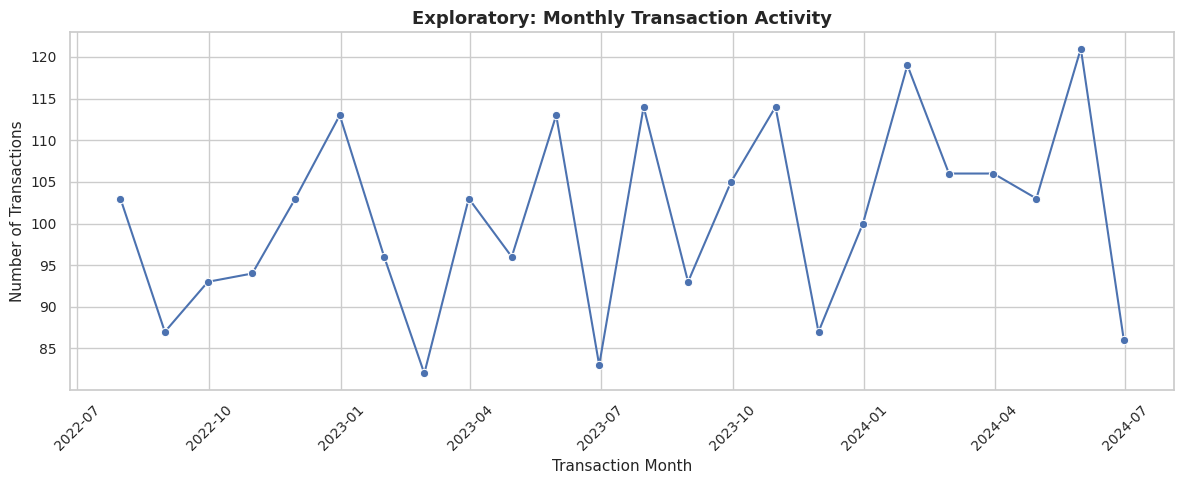

In [20]:
# @title Exploratory Monthly Transaction Activity

plt.figure(figsize=(12, 5))

sns.lineplot(
    data=monthly_transactions,
    x="transaction_date",
    y="transaction_count",
    marker="o"
)

plt.title("Exploratory: Monthly Transaction Activity")
plt.xlabel("Transaction Month")
plt.ylabel("Number of Transactions")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


#### Exploratory Review

The monthly transaction series provides a direct view of market activity and reveals meaningful month-to-month fluctuation.

**Visualization Decision:** **KEEP / REFINE.** Milestone 2 uses time-aligned small multiples for monthly transaction count and monthly total transaction value rather than a single activity measure.


## 3. Social Media Interactions

The social media interactions dataset contains FinMark customer activity across different platforms, including interaction type, sentiment, and interaction date.

This section explores how interactions are distributed across platforms, which interaction types occur most frequently, how sentiment is distributed, whether sentiment composition differs by platform or interaction type, and how social media activity changes over time.

The `customer_id` and `interaction_id` fields are treated as identifiers and are not analyzed as numerical features.

### Exploration Questions

| Analytical Question | Variable(s) | Candidate Visualization |
|---|---|---|
| Which social media platforms contain the most interactions? | `platform` | Count Plot, Bar Chart |
| Which interaction types occur most frequently? | `interaction_type` | Count Plot, Bar Chart |
| How are interactions distributed across sentiment categories? | `sentiment` | Count Plot, Bar Chart |
| Does sentiment composition differ across platforms? | `platform`, `sentiment` | Grouped Bar, 100% Stacked Bar |
| Does sentiment composition differ by interaction type? | `interaction_type`, `sentiment` | Grouped Bar, 100% Stacked Bar |
| How does recorded social media activity change over time? | `interaction_date` | Line Plot |
| Can sentiment be explored against time or engagement? | `sentiment`, `interaction_date`, `interaction_count` | Experimental Scatter Plot |


### 3.1 Social Media Category Frequencies

The `platform`, `interaction_type`, and `sentiment` variables are categorical.

Frequency and percentage summaries are reviewed before visualization to determine whether any categories dominate the dataset or whether the groups are relatively balanced.


In [21]:
# @title Social Media Frequency Summaries

def frequency_summary(df, column):
    summary = (
        df[column]
        .value_counts()
        .rename_axis(column)
        .reset_index(name="count")
    )

    summary["percentage"] = (
        summary["count"] / len(df) * 100
    )

    return summary


platform_summary = frequency_summary(
    social,
    "platform"
)

interaction_summary = frequency_summary(
    social,
    "interaction_type"
)

sentiment_summary = frequency_summary(
    social,
    "sentiment"
)

print("Platform Distribution")
display(
    platform_summary.style.format({
        "percentage": "{:.2f}%"
    })
)

print("Interaction Type Distribution")
display(
    interaction_summary.style.format({
        "percentage": "{:.2f}%"
    })
)

print("Sentiment Distribution")
display(
    sentiment_summary.style.format({
        "percentage": "{:.2f}%"
    })
)


Platform Distribution


,platform,count,percentage
0,Instagram,826,34.26%
1,Twitter,795,32.97%
2,Facebook,790,32.77%


Interaction Type Distribution


,interaction_type,count,percentage
0,Comment,808,33.51%
1,Share,808,33.51%
2,Like,795,32.97%


Sentiment Distribution


,sentiment,count,percentage
0,Neutral,790,32.77%
1,Positive,790,32.77%
2,Negative,780,32.35%
3,Very Positive,26,1.08%
4,Very Negative,25,1.04%


### 3.2 Platform and Interaction Type Visualization Options

Platform and interaction-type frequencies are visualized to determine whether recorded social media activity is concentrated on particular platforms or forms of interaction.

Count plots are used because they allow direct comparison of categorical frequencies, while count and percentage labels make small differences easier to evaluate.


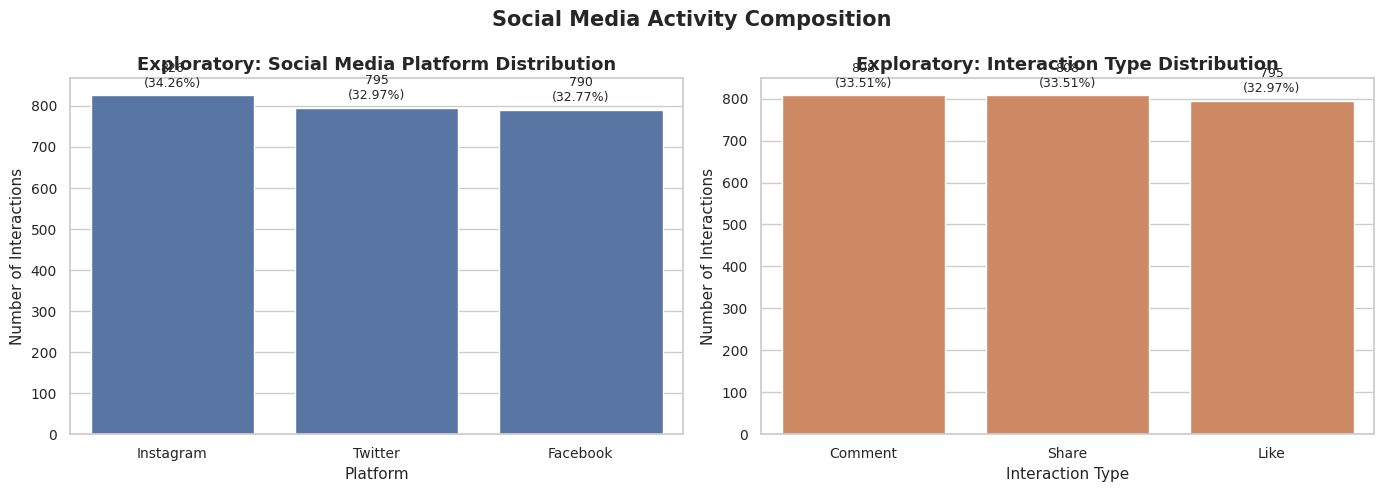

In [22]:
# @title Exploratory Platform and Interaction Type Visualizations

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

platform_order = (
    social["platform"]
    .value_counts()
    .index
)

sns.countplot(
    data=social,
    x="platform",
    order=platform_order,
    color=primary_color,
    ax=axes[0]
)

axes[0].set_title(
    "Exploratory: Social Media Platform Distribution"
)
axes[0].set_xlabel("Platform")
axes[0].set_ylabel("Number of Interactions")

add_count_labels(
    axes[0],
    len(social)
)

interaction_order = (
    social["interaction_type"]
    .value_counts()
    .index
)

sns.countplot(
    data=social,
    x="interaction_type",
    order=interaction_order,
    color=secondary_color,
    ax=axes[1]
)

axes[1].set_title(
    "Exploratory: Interaction Type Distribution"
)
axes[1].set_xlabel("Interaction Type")
axes[1].set_ylabel("Number of Interactions")

add_count_labels(
    axes[1],
    len(social)
)

fig.suptitle(
    "Social Media Activity Composition",
    fontweight="bold"
)

plt.tight_layout()
plt.show()


#### Exploratory Review

Platform and interaction-type counts are relatively balanced.

**Visualization Decision:** **DROP FROM FINAL.** They remain useful descriptive checks but do not provide a strong market or customer-behavior insight on their own.


### 3.3 Sentiment Distribution

Sentiment is explored to determine whether social media interactions are concentrated in particular sentiment categories and whether any categories are comparatively rare.

The sentiment categories are displayed in an ordered sequence from **Very Negative** to **Very Positive** to make interpretation easier.


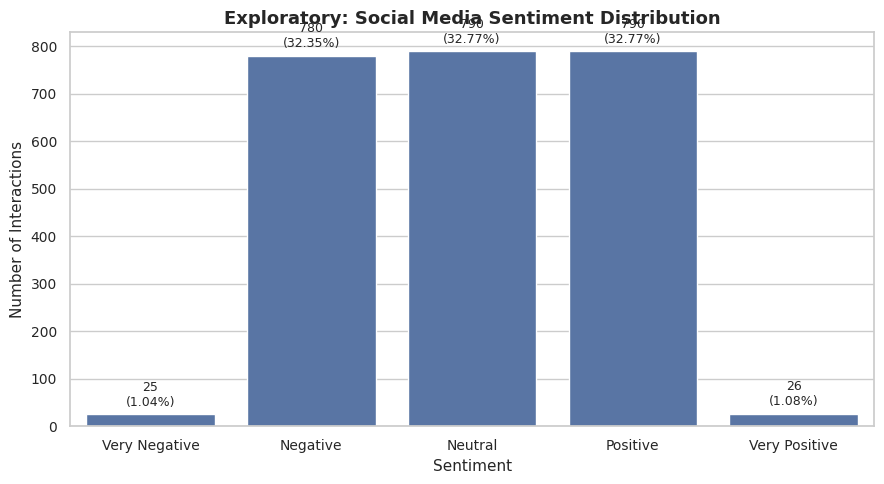

In [23]:
# @title Exploratory Sentiment Distribution

plt.figure(figsize=(9, 5))

ax = sns.countplot(
    data=social,
    x="sentiment",
    order=sentiment_order,
    color=primary_color
)

plt.title(
    "Exploratory: Social Media Sentiment Distribution"
)
plt.xlabel("Sentiment")
plt.ylabel("Number of Interactions")

add_count_labels(
    ax,
    len(social)
)

plt.tight_layout()
plt.show()


#### Exploratory Review

The sentiment distribution establishes the overall balance of sentiment categories.

**Visualization Decision:** **REFINE.** Rather than keeping a static sentiment count chart as a headline visual, Milestone 2 uses monthly sentiment composition to show how the mix changes over time.


### 3.4 Sentiment Composition by Platform

Platform and sentiment are combined to explore whether the distribution of sentiment differs across Facebook, Instagram, and Twitter.

Two candidate visualizations are tested:

- **Grouped Bar Chart:** Compares raw sentiment counts across platforms.
- **100% Stacked Bar Chart:** Compares the proportion of each sentiment category within each platform.

The percentage-based version may be more useful when the objective is to compare sentiment composition rather than total platform volume.


In [24]:
# @title Platform and Sentiment Summary

platform_sentiment_counts = pd.crosstab(
    social["platform"],
    social["sentiment"]
)

platform_sentiment_pct = pd.crosstab(
    social["platform"],
    social["sentiment"],
    normalize="index"
) * 100

platform_sentiment_pct = (
    platform_sentiment_pct
    .reindex(columns=sentiment_order)
)

display(
    platform_sentiment_pct.style.format(
        "{:.2f}%"
    )
)


sentiment,Very Negative,Negative,Neutral,Positive,Very Positive
platform,,,,,
Facebook,1.65%,31.01%,33.16%,33.42%,0.76%
Instagram,0.61%,32.81%,30.87%,34.38%,1.33%
Twitter,0.88%,33.21%,34.34%,30.44%,1.13%


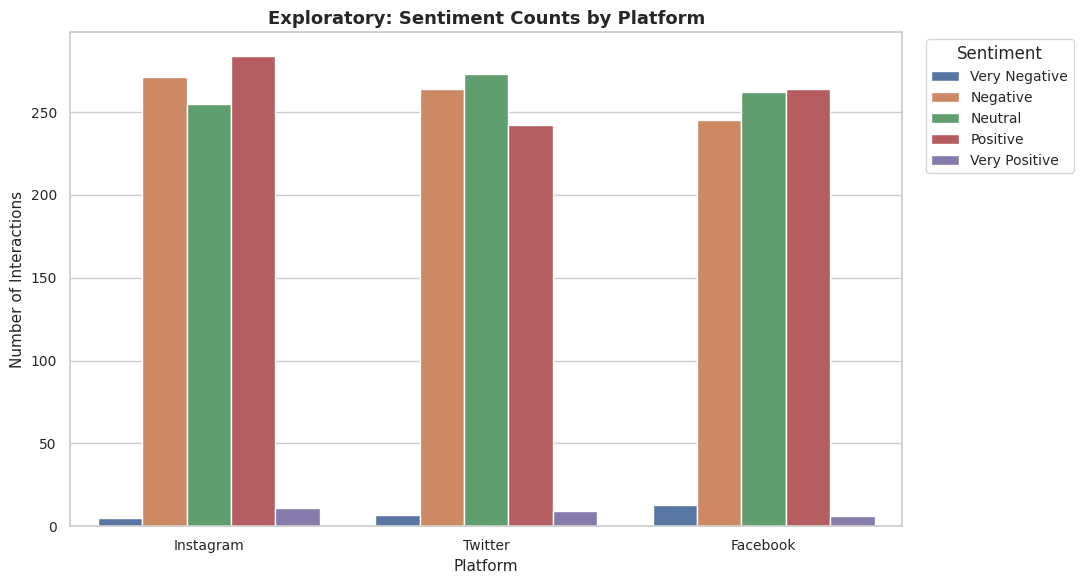

In [25]:
# @title Exploratory Grouped Sentiment by Platform

plt.figure(figsize=(11, 6))

sns.countplot(
    data=social,
    x="platform",
    hue="sentiment",
    hue_order=sentiment_order
)

plt.title(
    "Exploratory: Sentiment Counts by Platform"
)
plt.xlabel("Platform")
plt.ylabel("Number of Interactions")
plt.legend(
    title="Sentiment",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()


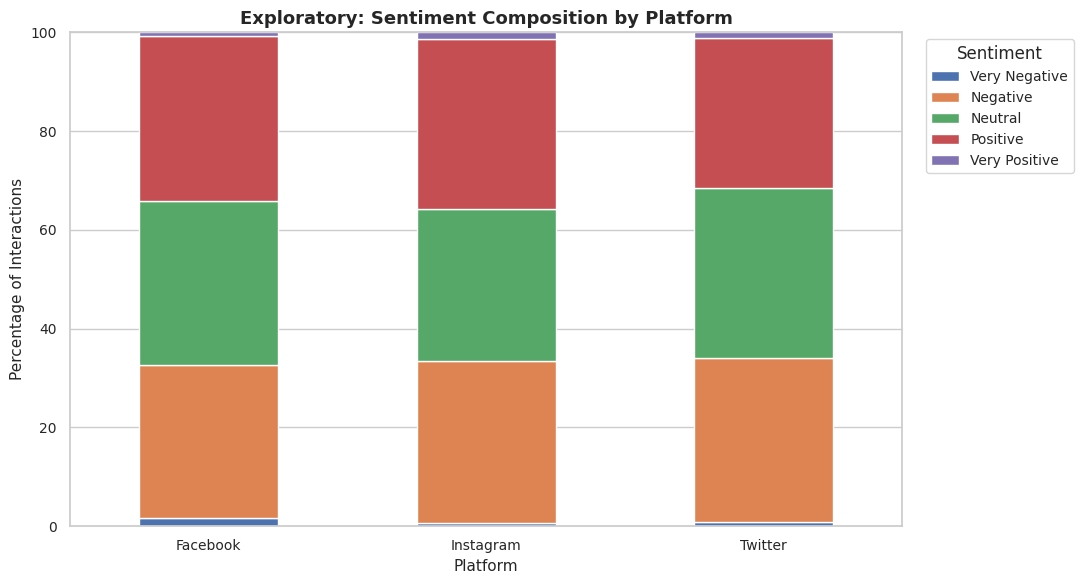

In [26]:
# @title Exploratory Sentiment Composition by Platform

platform_sentiment_pct.plot(
    kind="bar",
    stacked=True,
    figsize=(11, 6)
)

plt.title(
    "Exploratory: Sentiment Composition by Platform"
)
plt.xlabel("Platform")
plt.ylabel("Percentage of Interactions")
plt.legend(
    title="Sentiment",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.tight_layout()
plt.show()


#### Exploratory Review

Platform-level sentiment compositions are similar enough that a platform comparison adds limited decision value.

**Visualization Decision:** **DROP FROM FINAL.** Monthly sentiment composition provides a clearer market-dynamics question.


### 3.5 Sentiment Composition by Interaction Type

Interaction type and sentiment are combined to explore whether likes, comments, and shares show different sentiment compositions.

This analysis is exploratory and will only be retained if the visualization reveals a meaningful pattern that adds information beyond the platform analysis.


In [27]:
# @title Interaction Type and Sentiment Summary

interaction_sentiment_pct = pd.crosstab(
    social["interaction_type"],
    social["sentiment"],
    normalize="index"
) * 100

interaction_sentiment_pct = (
    interaction_sentiment_pct
    .reindex(columns=sentiment_order)
)

display(
    interaction_sentiment_pct.style.format(
        "{:.2f}%"
    )
)


sentiment,Very Negative,Negative,Neutral,Positive,Very Positive
interaction_type,,,,,
Comment,1.86%,32.43%,33.17%,31.68%,0.87%
Like,0.25%,33.21%,32.96%,32.45%,1.13%
Share,0.99%,31.44%,32.18%,34.16%,1.24%


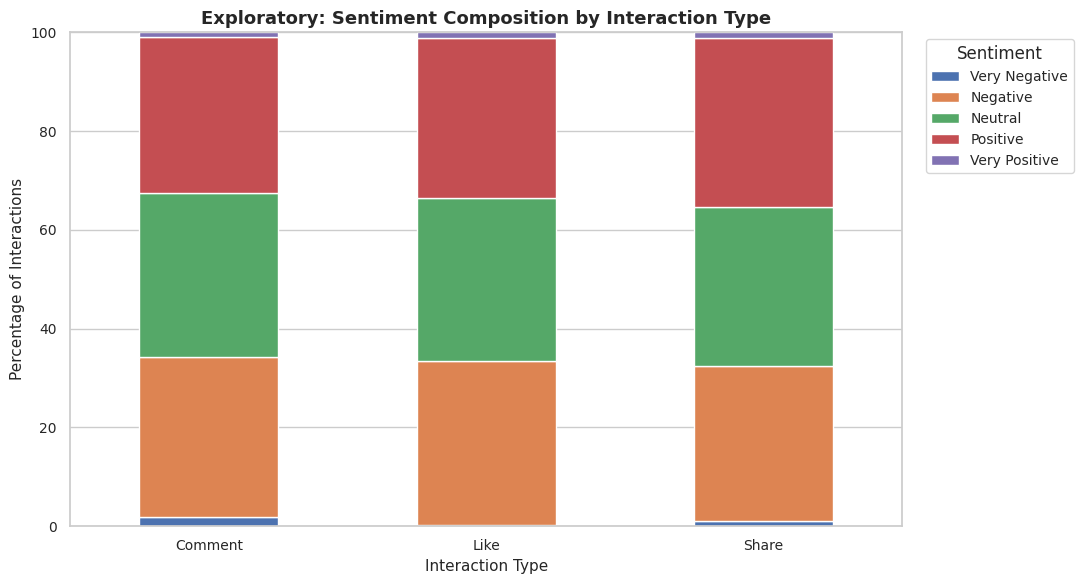

In [28]:
# @title Exploratory Sentiment Composition by Interaction Type

interaction_sentiment_pct.plot(
    kind="bar",
    stacked=True,
    figsize=(11, 6)
)

plt.title(
    "Exploratory: Sentiment Composition by Interaction Type"
)
plt.xlabel("Interaction Type")
plt.ylabel("Percentage of Interactions")

plt.legend(
    title="Sentiment",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.tight_layout()
plt.show()


#### Exploratory Review

Sentiment composition across interaction types does not reveal a strong differentiating pattern.

**Visualization Decision:** **DROP FROM FINAL.** Retain as exploratory evidence only.


### 3.6 Monthly Social Media Activity

Interaction dates are aggregated by month to examine changes in recorded social media activity over time.

A line chart is used because the chronological order of the monthly observations is important when identifying increases, decreases, and fluctuations.


In [29]:
# @title Prepare Monthly Social Media Activity

social["interaction_date"] = pd.to_datetime(
    social["interaction_date"]
)

monthly_social = (
    social
    .set_index("interaction_date")
    .resample("ME")
    .size()
    .reset_index(name="interaction_count")
)

display(monthly_social.head())


,interaction_date,interaction_count
0,2023-07-31,212
1,2023-08-31,188
2,2023-09-30,195
3,2023-10-31,209
4,2023-11-30,180


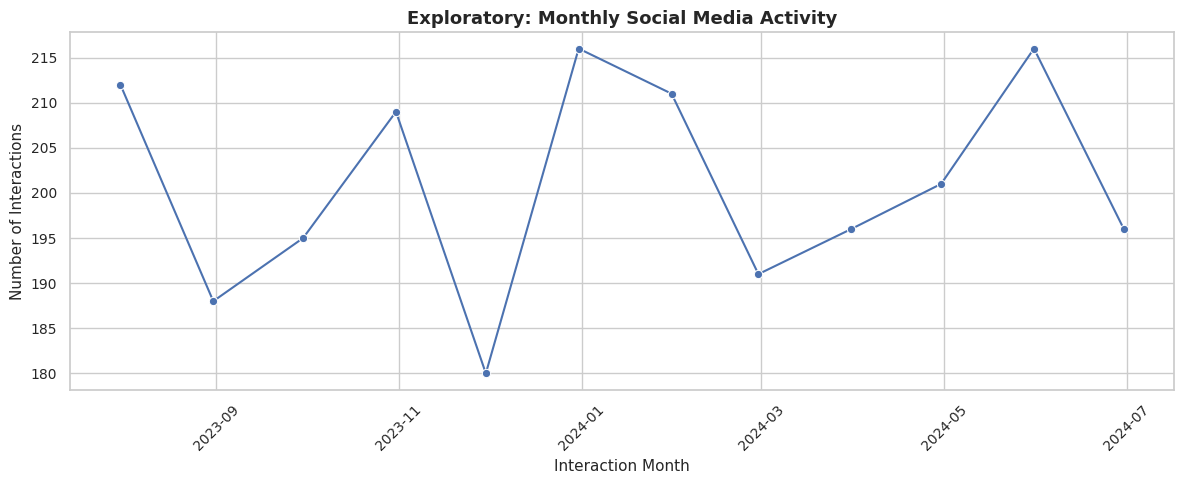

In [30]:
# @title Exploratory Monthly Social Media Activity

plt.figure(figsize=(12, 5))

sns.lineplot(
    data=monthly_social,
    x="interaction_date",
    y="interaction_count",
    marker="o"
)

plt.title(
    "Exploratory: Monthly Social Media Activity"
)
plt.xlabel("Interaction Month")
plt.ylabel("Number of Interactions")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


#### Exploratory Review

Monthly social activity shows volume changes, but simple interaction count does not explain sentiment or purchasing behavior.

**Visualization Decision:** **REFINE.** Milestone 2 prioritizes monthly **sentiment composition** instead of monthly interaction volume as the main social-media time view.


### 3.7 Experimental Sentiment Scatter Plots

Sentiment is originally a categorical variable, so it cannot be used directly as a numerical scatter-plot axis.

For exploratory purposes, the ordered sentiment categories are temporarily encoded using an ordinal index:

| Sentiment | Ordinal Index |
|---|---:|
| Very Negative | -2 |
| Negative | -1 |
| Neutral | 0 |
| Positive | 1 |
| Very Positive | 2 |

This encoding allows sentiment observations to be explored visually across time. The index values are used only to preserve the order of sentiment categories and should not be interpreted as precise numerical distances between emotional states.

The scatter plot is tested to determine whether individual sentiment observations reveal time-based clustering, concentration, or unusual patterns that are not as visible in the frequency charts.


In [31]:
# @title Prepare Exploratory Sentiment Scores

social["sentiment_index"] = (
    social["sentiment"]
    .map(sentiment_index_map)
)

social["interaction_date"] = pd.to_datetime(
    social["interaction_date"]
)

display(
    social[
        [
            "interaction_date",
            "platform",
            "sentiment",
            "sentiment_index"
        ]
    ].head()
)


,interaction_date,platform,sentiment,sentiment_index
0,2024-05-24,Instagram,Neutral,0
1,2023-11-01,Instagram,Neutral,0
2,2023-12-18,Instagram,Positive,1
3,2023-11-15,Instagram,Positive,1
4,2024-05-28,Twitter,Positive,1


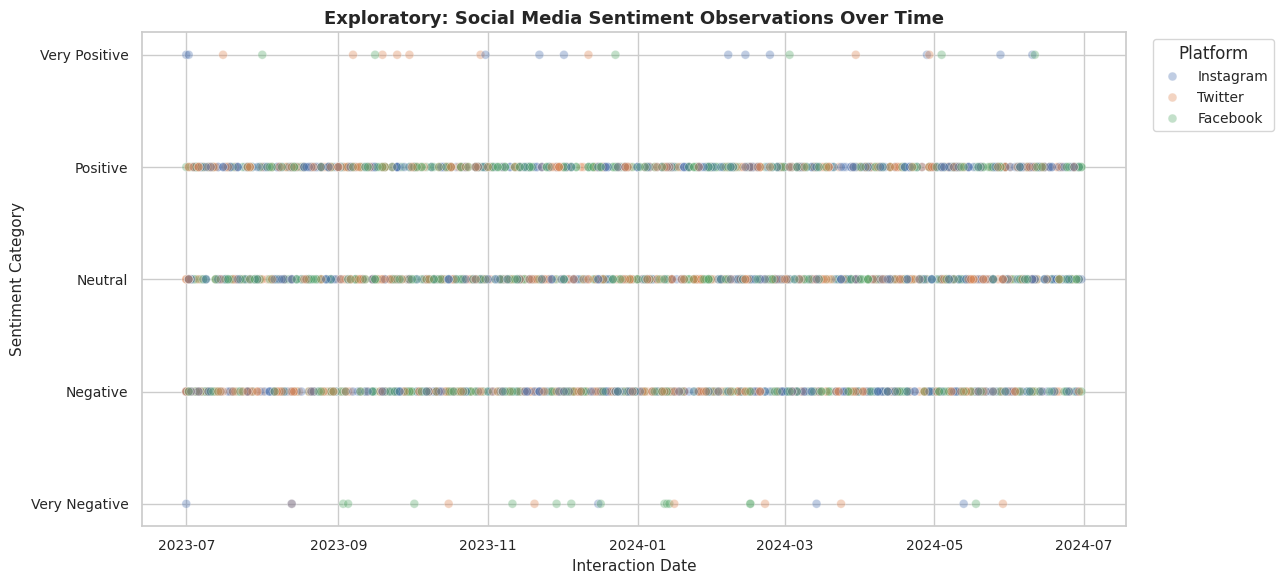

In [32]:
# @title Exploratory Sentiment Observations Over Time

plt.figure(figsize=(13, 6))

sns.scatterplot(
    data=social,
    x="interaction_date",
    y="sentiment_index",
    hue="platform",
    alpha=0.35,
    s=40
)

plt.title(
    "Exploratory: Social Media Sentiment Observations Over Time"
)
plt.xlabel("Interaction Date")
plt.ylabel("Sentiment Category")

plt.yticks(
    [-2, -1, 0, 1, 2],
    [
        "Very Negative",
        "Negative",
        "Neutral",
        "Positive",
        "Very Positive"
    ]
)

plt.legend(
    title="Platform",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()


In [33]:
# @title Prepare Customer-Level Social Media Metrics

customer_social = (
    social
    .groupby("customer_id")
    .agg(
        interaction_count=("interaction_id", "count"),
        average_sentiment_index=("sentiment_index", "mean")
    )
    .reset_index()
)

display(customer_social.head())


,customer_id,interaction_count,average_sentiment_index
0,0009fdd2-ae63-45ca-8d5b-d0ea98381f7b,2,0.500000
1,000c6bbd-533a-432d-922c-ab64197e71c5,3,0.333333
2,00145374-004a-4685-af4d-c8a8967b969e,2,-0.500000
3,00c15eff-8bcf-4d12-a5d4-992e45e3309f,2,0.000000
4,00d4fbfe-5ce0-4d87-a307-b15801d1373e,1,-1.000000


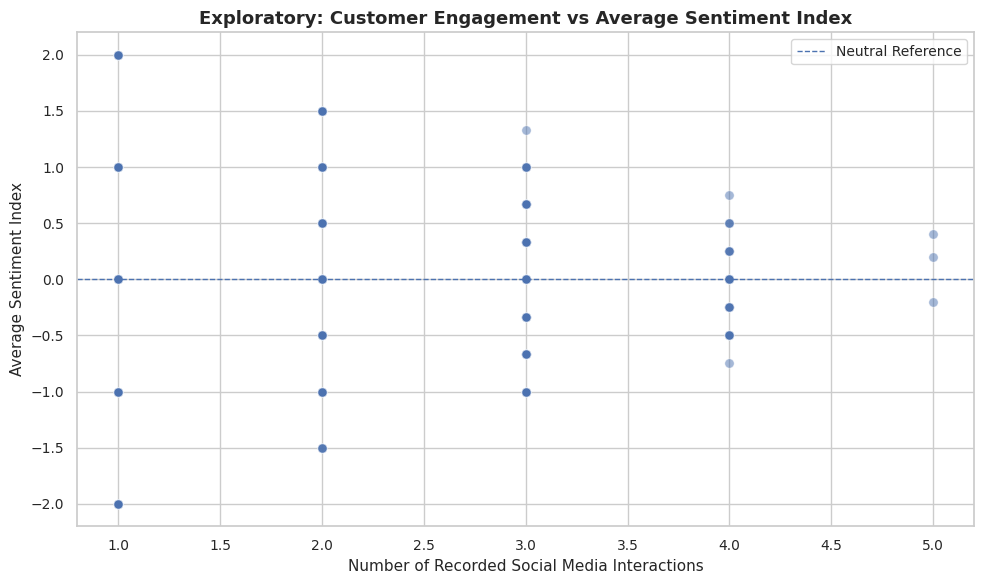

In [34]:
# @title Exploratory Engagement and Average Sentiment Scatter Plot

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=customer_social,
    x="interaction_count",
    y="average_sentiment_index",
    alpha=0.5,
    s=45
)

plt.axhline(
    0,
    linestyle="--",
    linewidth=1,
    label="Neutral Reference"
)

plt.title(
    "Exploratory: Customer Engagement vs Average Sentiment Index"
)
plt.xlabel("Number of Recorded Social Media Interactions")
plt.ylabel("Average Sentiment Index")

plt.legend()

plt.tight_layout()
plt.show()


In [35]:
# @title Engagement and Sentiment Rank Correlation

engagement_sentiment_corr = (
    customer_social[
        ["interaction_count", "average_sentiment_index"]
    ]
    .corr(method="spearman")
    .iloc[0, 1]
)

print(
    f"Spearman correlation between interaction count "
    f"and average sentiment index: "
    f"{engagement_sentiment_corr:.2f}"
)


Spearman correlation between interaction count and average sentiment index: -0.00


#### Exploratory Review

The sentiment scatter experiments are visually dense and depend on an ordinal sentiment encoding.

**Visualization Decision:** **DROP FROM FINAL.** The categorical monthly sentiment-composition view is clearer and avoids implying precise numerical distance between sentiment labels.


# Part II: Cross-Dataset Exploration

The previous sections examined the demographics, transaction, and social media datasets independently.

This section explores selected relationships across datasets. Cross-dataset combinations are included only when they support a meaningful FinMark analytical question.

Because the transaction and social media datasets can contain multiple records for the same customer, event-level records are not directly joined together. Where necessary, records are first aggregated to the customer level before merging.

This prevents many-to-many duplication and ensures that each customer contributes appropriately to customer-level analysis.


## 4. Customer Demographics and Transaction Behavior

Customer demographics are combined with aggregated transaction information to explore whether customer characteristics are associated with purchasing behavior.

Transaction records are first summarized at the `customer_id` level so that each customer contributes one customer-level transaction profile before the data is matched with demographics.

### Derived Transaction Metrics

| Metric | Meaning |
|---|---|
| `total_spend` | Total recorded transaction amount per customer |
| `transaction_count` | Number of recorded transactions per customer |
| `average_transaction_amount` | Average recorded transaction amount per customer |

### Exploration Questions

| Analytical Question | Variables | Candidate Visualization |
|---|---|---|
| Does total spending differ across income groups? | `income_level`, `total_spend` | Box Plot, Median Bar Chart |
| Is customer age associated with total spending? | `age`, `total_spend` | Scatter Plot, Regression Plot |
| Does transaction frequency differ across income groups? | `income_level`, `transaction_count` | Box Plot, Mean Bar Chart |


### 4.1 Prepare the Matched Demographics-Transaction Dataset

Transaction records are aggregated to one row per customer before the customer-level transaction metrics are matched with the demographics dataset.


In [36]:
# @title Prepare Customer-Level Transaction Metrics

customer_transactions = (
    transactions
    .groupby("customer_id")
    .agg(
        total_spend=("amount", "sum"),
        transaction_count=("transaction_id", "count"),
        average_transaction_amount=("amount", "mean")
    )
    .reset_index()
)

display(customer_transactions.head())


,customer_id,total_spend,transaction_count,average_transaction_amount
0,0009fdd2-ae63-45ca-8d5b-d0ea98381f7b,389.69,1,389.690
1,00115fc0-f155-42cd-ba68-58aab67b3360,153.89,1,153.890
2,0047d8ce-a5bb-4db7-860f-6ff66e1cd060,259.47,1,259.470
3,0064a8b2-71d3-41c1-a46a-6eea56fdff91,2755.14,4,688.785
4,00742b15-bab0-440f-a085-221ce13d95a0,153.09,1,153.090


In [37]:
# @title Merge Demographics with Customer Transaction Metrics

demo_transactions = demographics.merge(
    customer_transactions,
    on="customer_id",
    how="inner"
)

print(f"Demographic customers: {demographics['customer_id'].nunique():,}")
print(f"Customers with transactions: {customer_transactions['customer_id'].nunique():,}")
print(f"Matched customers: {demo_transactions['customer_id'].nunique():,}")

display(demo_transactions.head())


Demographic customers: 2,378
Customers with transactions: 1,642
Matched customers: 1,306


,customer_id,age,gender,location,income_level,signup_date,total_spend,transaction_count,average_transaction_amount
0,9207fa75-5758-48d1-94ad-19c041e0520f,51,Female,Jensenberg,Low,2022-11-17,660.87,1,660.870000
1,7d1f2bbc-8d16-4fbc-9b37-ece3324e8ed4,50,Female,Jessebury,High,2023-08-24,733.46,1,733.460000
2,2de49c7c-32ae-4ba8-b058-622a090d7094,53,Female,Emilyville,Low,2022-02-13,891.74,3,297.246667
3,8602d631-457c-49c1-8b59-8efb2a4448d4,51,Male,East Keithville,High,2022-04-17,815.21,1,815.210000
4,3f520998-2bc4-4f38-af82-5ab2de339984,59,Female,Smithside,High,2023-10-06,183.91,1,183.910000


#### Matched Population

The cross-dataset analysis uses only customers whose `customer_id` appears in both the cleaned demographics and transaction datasets.

Results from this section therefore describe the **matched customer subset**, not every customer in either original dataset.


### 4.2 Total Spending by Income Level

Income level and total customer spending are combined to explore whether purchasing behavior differs across demographic income groups.

Two candidate visualizations are tested:

- **Box Plot:** Shows the distribution, median, spread, and potential unusual customer spending values within each income group.
- **Median Bar Chart:** Provides a simpler comparison of typical total spending between groups.

The comparison is descriptive and does not imply that income level causes differences in spending.


In [38]:
# @title Income Level and Total Spending Summary

income_spend_summary = (
    demo_transactions
    .groupby("income_level")
    .agg(
        customers=("customer_id", "nunique"),
        mean_total_spend=("total_spend", "mean"),
        median_total_spend=("total_spend", "median"),
        mean_transaction_count=("transaction_count", "mean")
    )
    .reindex(["Low", "Medium", "High"])
    .reset_index()
)

display(
    income_spend_summary.style.format({
        "mean_total_spend": "{:,.2f}",
        "median_total_spend": "{:,.2f}",
        "mean_transaction_count": "{:.2f}"
    })
)


,income_level,customers,mean_total_spend,median_total_spend,mean_transaction_count
0,Low,429,746.66,688.17,1.50
1,Medium,417,728.20,658.38,1.48
2,High,460,708.41,658.80,1.45


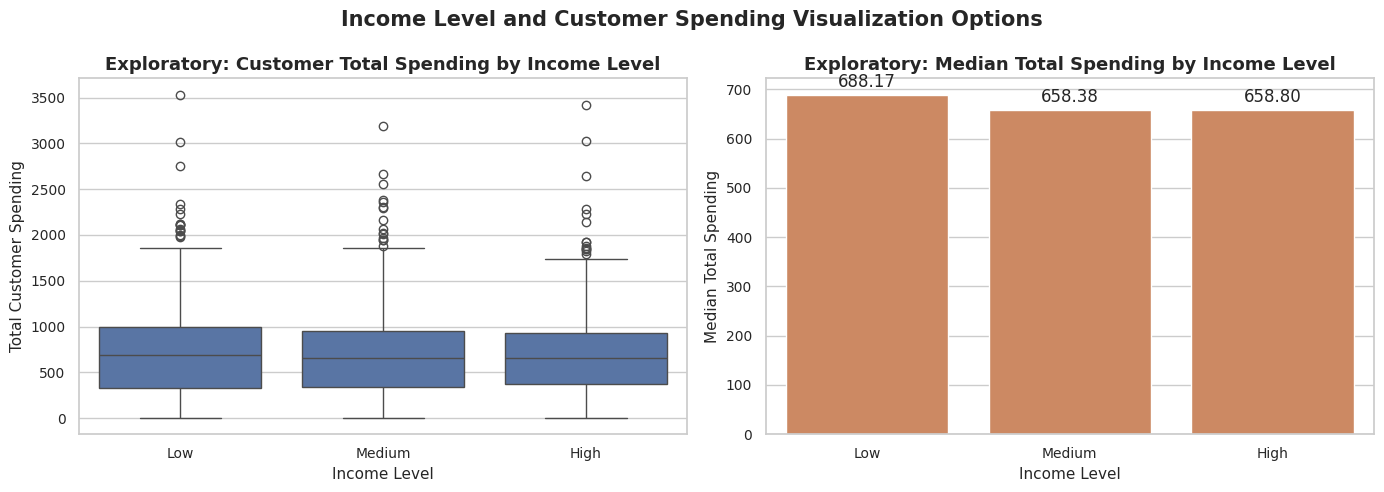

In [39]:
# @title Exploratory Income Level and Total Spending

income_order = ["Low", "Medium", "High"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(
    data=demo_transactions,
    x="income_level",
    y="total_spend",
    order=income_order,
    ax=axes[0]
)

axes[0].set_title(
    "Exploratory: Customer Total Spending by Income Level"
)
axes[0].set_xlabel("Income Level")
axes[0].set_ylabel("Total Customer Spending")


sns.barplot(
    data=income_spend_summary,
    x="income_level",
    y="median_total_spend",
    order=income_order,
    color=secondary_color,
    ax=axes[1]
)

axes[1].set_title(
    "Exploratory: Median Total Spending by Income Level"
)
axes[1].set_xlabel("Income Level")
axes[1].set_ylabel("Median Total Spending")

for container in axes[1].containers:
    axes[1].bar_label(
        container,
        fmt="%.2f",
        padding=3
    )

fig.suptitle(
    "Income Level and Customer Spending Visualization Options",
    fontweight="bold"
)

plt.tight_layout()
plt.show()


#### Exploratory Review

Income groups show substantial overlap in customer spending.

**Visualization Decision:** **DROP FROM FINAL.** The comparison does not provide a sufficiently strong segmentation signal for the focused Milestone 2 narrative.


### 4.3 Customer Age and Total Spending

Customer age and total spending are both numerical variables, making a scatter plot appropriate for exploring their relationship.

The visualization is supported by a Pearson correlation coefficient to measure the strength and direction of any linear association.


In [40]:
# @title Age and Total Spending Correlation

age_spend_corr = np.corrcoef(
    demo_transactions["age"],
    demo_transactions["total_spend"]
)[0, 1]

print(
    f"Correlation between customer age and total spending: "
    f"{age_spend_corr:.2f}"
)


Correlation between customer age and total spending: 0.00


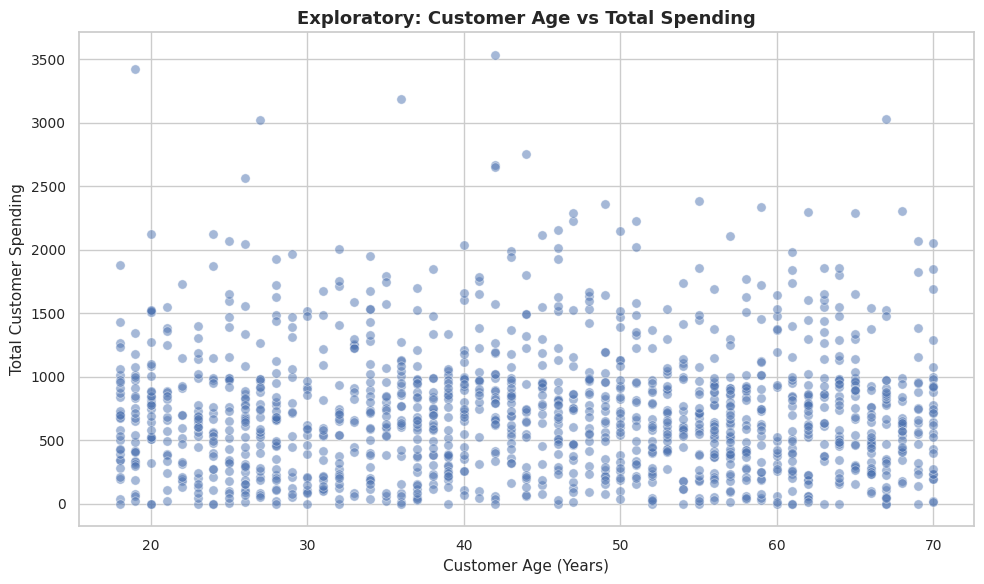

In [41]:
# @title Exploratory Customer Age vs Total Spending

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=demo_transactions,
    x="age",
    y="total_spend",
    alpha=0.5,
    s=45
)

plt.title(
    "Exploratory: Customer Age vs Total Spending"
)
plt.xlabel("Customer Age (Years)")
plt.ylabel("Total Customer Spending")

plt.tight_layout()
plt.show()


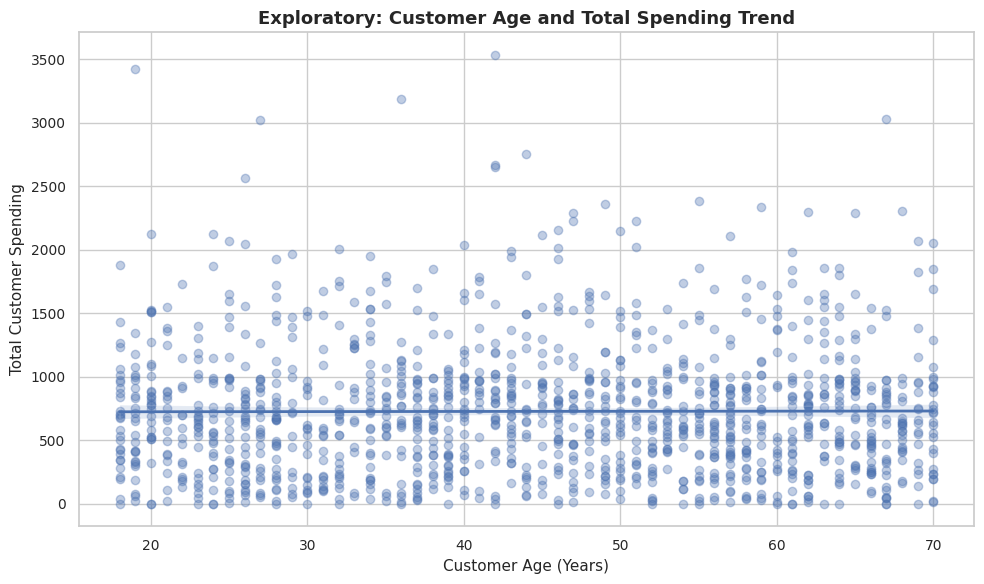

In [42]:
# @title Exploratory Age and Spending Trend

plt.figure(figsize=(10, 6))

sns.regplot(
    data=demo_transactions,
    x="age",
    y="total_spend",
    scatter_kws={"alpha": 0.35},
    line_kws={"linewidth": 2}
)

plt.title(
    "Exploratory: Customer Age and Total Spending Trend"
)
plt.xlabel("Customer Age (Years)")
plt.ylabel("Total Customer Spending")

plt.tight_layout()
plt.show()


#### Exploratory Review

Customer age shows almost no linear relationship with total spending.

**Visualization Decision:** **DROP FROM FINAL.** The exploratory result is still useful because it prevents age from being treated as a strong standalone purchasing signal.


### 4.4 Transaction Frequency by Income Level

This analysis examines whether the number of recorded transactions per customer differs across income groups.

Because `transaction_count` is measured at the customer level, the comparison avoids allowing customers with multiple transaction records to be counted as separate customers.


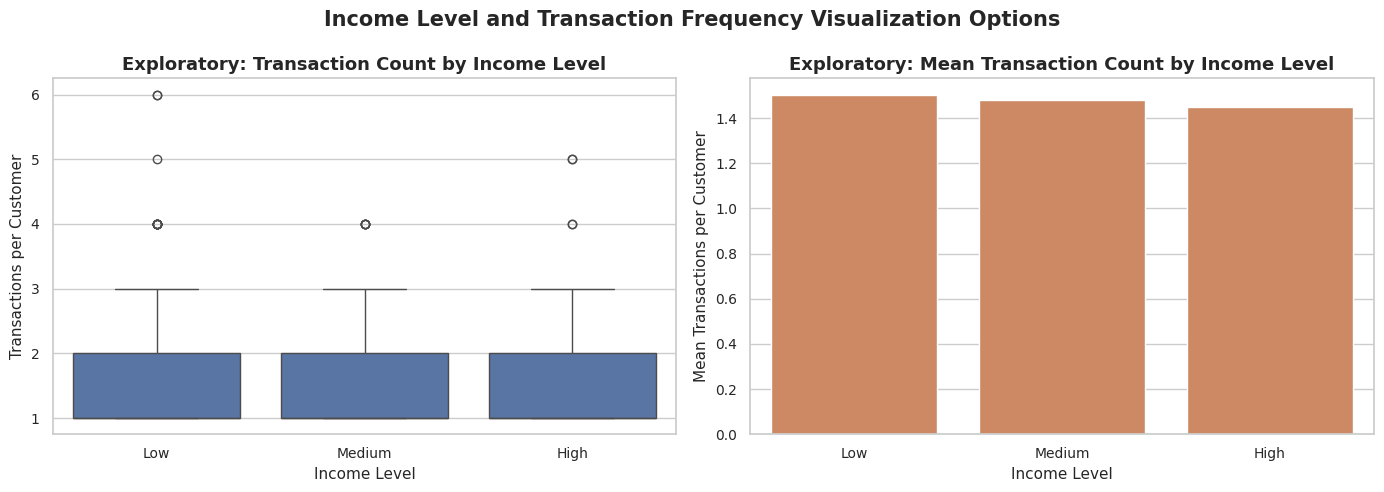

In [43]:
# @title Exploratory Transaction Frequency by Income Level

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(
    data=demo_transactions,
    x="income_level",
    y="transaction_count",
    order=income_order,
    ax=axes[0]
)

axes[0].set_title(
    "Exploratory: Transaction Count by Income Level"
)
axes[0].set_xlabel("Income Level")
axes[0].set_ylabel("Transactions per Customer")


sns.barplot(
    data=demo_transactions,
    x="income_level",
    y="transaction_count",
    order=income_order,
    estimator=np.mean,
    errorbar=None,
    color=secondary_color,
    ax=axes[1]
)

axes[1].set_title(
    "Exploratory: Mean Transaction Count by Income Level"
)
axes[1].set_xlabel("Income Level")
axes[1].set_ylabel("Mean Transactions per Customer")

fig.suptitle(
    "Income Level and Transaction Frequency Visualization Options",
    fontweight="bold"
)

plt.tight_layout()
plt.show()


#### Exploratory Review

Transaction-frequency distributions overlap considerably across income groups.

**Visualization Decision:** **DROP FROM FINAL.** The differences are too small to support a strong income-based purchasing story.


## 5. Customer Demographics and Social Media Engagement

Customer demographic information is combined with aggregated social media interaction data to explore whether recorded engagement differs across customer characteristics.

Because the social media dataset can contain multiple interactions for the same customer, interaction records are first aggregated at the `customer_id` level before being merged with the demographics dataset.

This analysis focuses on customer engagement frequency rather than treating individual social media interactions as separate customers.

### Derived Social Media Metrics

| Metric | Meaning |
|---|---|
| `interaction_count` | Number of recorded social media interactions per customer |
| `average_sentiment_index` | Exploratory mean of the ordinal sentiment index per customer |

### Exploration Questions

| Analytical Question | Variables | Candidate Visualization |
|---|---|---|
| Is customer age associated with social media engagement? | `age`, `interaction_count` | Scatter Plot |
| Does engagement frequency differ across income groups? | `income_level`, `interaction_count` | Box Plot, Mean Bar Chart |
| Does the exploratory sentiment index differ across income groups? | `income_level`, `average_sentiment_index` | Box Plot, Mean Bar Chart |


### 5.1 Prepare the Matched Demographics-Social Media Dataset

The customer-level social media summary prepared in Section 3.7 is matched with the demographics dataset using `customer_id`.

This preserves one row per matched customer and avoids treating individual social media interactions as separate customers.


In [44]:
# @title Merge Demographics with Customer Social Media Metrics

demo_social = demographics.merge(
    customer_social,
    on="customer_id",
    how="inner"
)

print(
    f"Demographic customers: "
    f"{demographics['customer_id'].nunique():,}"
)

print(
    f"Customers with social media interactions: "
    f"{customer_social['customer_id'].nunique():,}"
)

print(
    f"Matched customers: "
    f"{demo_social['customer_id'].nunique():,}"
)

display(demo_social.head())


Demographic customers: 2,378
Customers with social media interactions: 1,640
Matched customers: 1,304


,customer_id,age,gender,location,income_level,signup_date,interaction_count,average_sentiment_index
0,9207fa75-5758-48d1-94ad-19c041e0520f,51,Female,Jensenberg,Low,2022-11-17,2,0.0
1,50118139-7264-428f-81cc-a25fddc5d6dd,44,Male,Port Carl,Medium,2024-06-10,2,-0.5
2,7d1f2bbc-8d16-4fbc-9b37-ece3324e8ed4,50,Female,Jessebury,High,2023-08-24,2,0.0
3,2de49c7c-32ae-4ba8-b058-622a090d7094,53,Female,Emilyville,Low,2022-02-13,3,1.0
4,8602d631-457c-49c1-8b59-8efb2a4448d4,51,Male,East Keithville,High,2022-04-17,2,0.5


#### Matched Population

This section includes only customers whose `customer_id` appears in both the cleaned demographics and social media datasets.

The results therefore describe the matched customer subset rather than every customer in either source dataset.


### 5.2 Customer Age and Social Media Engagement

Customer age and interaction count are combined to explore whether recorded social media engagement varies with age.

A scatter plot is used because both variables are numerical at the customer level.

A Pearson correlation coefficient is also calculated to provide numerical support for the visual assessment.


In [45]:
# @title Age and Social Media Engagement Correlation

age_engagement_corr = np.corrcoef(
    demo_social["age"],
    demo_social["interaction_count"]
)[0, 1]

print(
    f"Correlation between customer age and interaction count: "
    f"{age_engagement_corr:.2f}"
)


Correlation between customer age and interaction count: 0.02


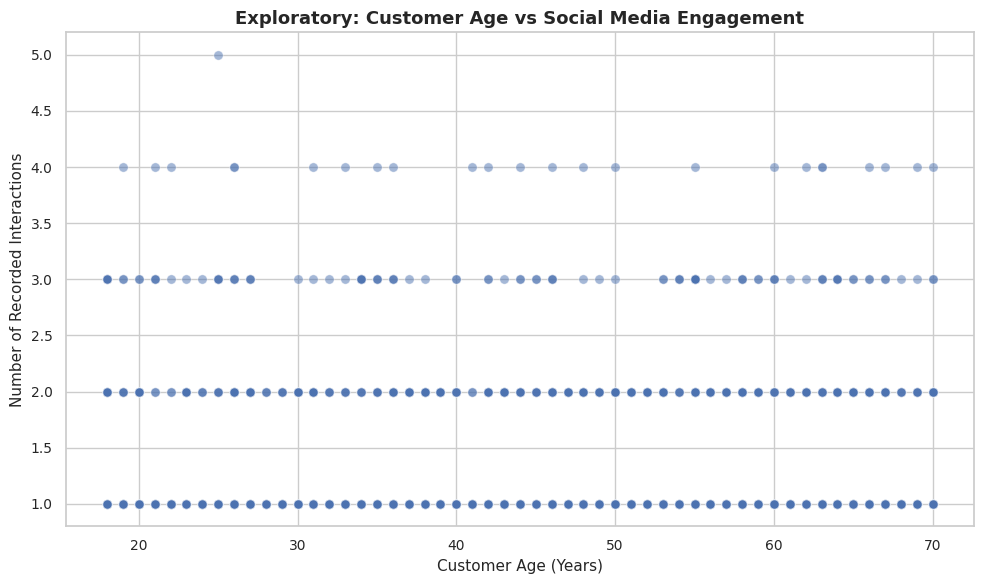

In [46]:
# @title Exploratory Customer Age vs Social Media Engagement

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=demo_social,
    x="age",
    y="interaction_count",
    alpha=0.5,
    s=45
)

plt.title(
    "Exploratory: Customer Age vs Social Media Engagement"
)

plt.xlabel("Customer Age (Years)")
plt.ylabel("Number of Recorded Interactions")

plt.tight_layout()
plt.show()


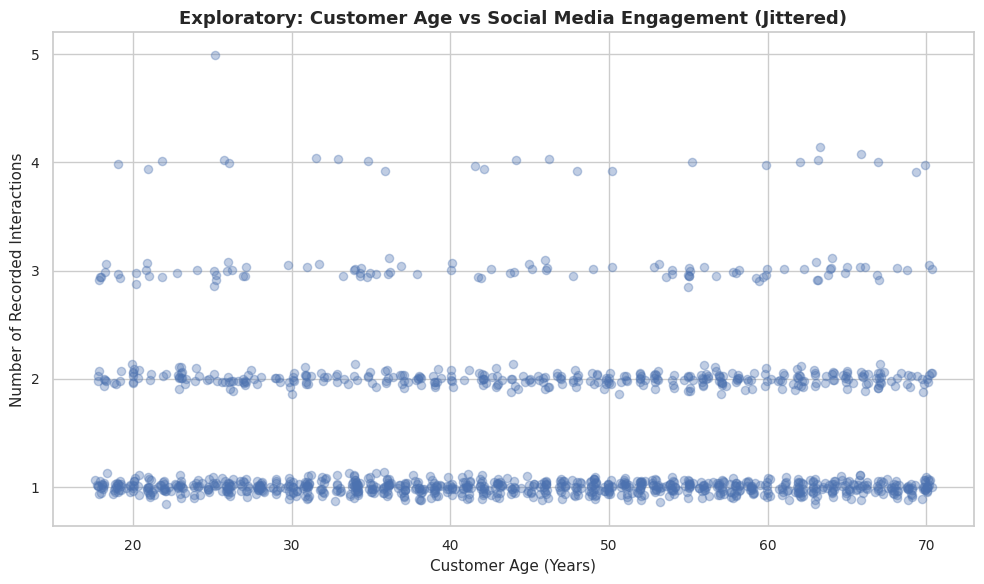

In [47]:
# @title Exploratory Age and Engagement with Jitter

rng = np.random.default_rng(42)

plot_age = (
    demo_social["age"]
    + rng.normal(
        0,
        0.18,
        len(demo_social)
    )
)

plot_interactions = (
    demo_social["interaction_count"]
    + rng.normal(
        0,
        0.05,
        len(demo_social)
    )
)

plt.figure(figsize=(10, 6))

plt.scatter(
    plot_age,
    plot_interactions,
    alpha=0.35,
    s=35
)

plt.title(
    "Exploratory: Customer Age vs Social Media Engagement (Jittered)"
)

plt.xlabel("Customer Age (Years)")
plt.ylabel("Number of Recorded Interactions")

plt.tight_layout()
plt.show()


#### Exploratory Review

Customer age and recorded social-media interaction frequency do not show a clear relationship.

**Visualization Decision:** **DROP FROM FINAL.** The exploratory result does not justify a headline visualization.


### 5.3 Social Media Engagement by Income Level

Customer income level is combined with interaction count to examine whether recorded engagement frequency differs across income groups.

Two visualization approaches are tested:

- **Box Plot:** Shows the distribution and spread of interaction counts within each income group.
- **Mean Bar Chart:** Provides a simpler comparison of average recorded interaction frequency.


In [48]:
# @title Income Level and Social Media Engagement Summary

income_engagement_summary = (
    demo_social
    .groupby("income_level")
    .agg(
        customers=("customer_id", "nunique"),
        mean_interactions=("interaction_count", "mean"),
        median_interactions=("interaction_count", "median"),
        std_interactions=("interaction_count", "std")
    )
    .reindex(["Low", "Medium", "High"])
    .reset_index()
)

display(
    income_engagement_summary.style.format({
        "mean_interactions": "{:.2f}",
        "median_interactions": "{:.2f}",
        "std_interactions": "{:.2f}"
    })
)


,income_level,customers,mean_interactions,median_interactions,std_interactions
0,Low,441,1.49,1.00,0.72
1,Medium,413,1.45,1.00,0.71
2,High,450,1.48,1.00,0.73


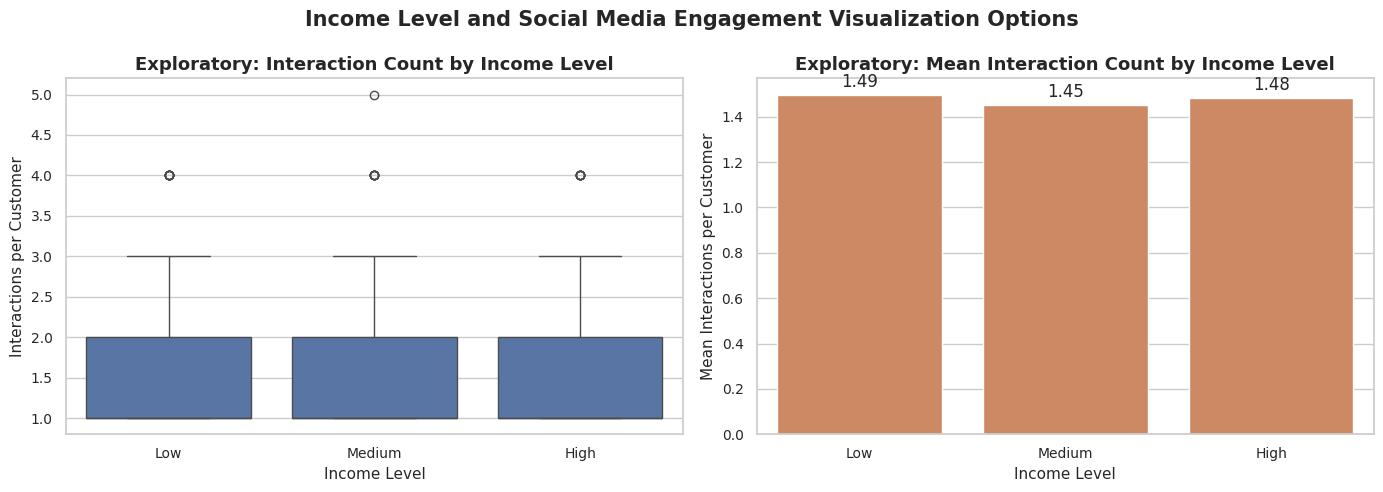

In [49]:
# @title Exploratory Social Media Engagement by Income Level

income_order = ["Low", "Medium", "High"]

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5)
)

# Distribution
sns.boxplot(
    data=demo_social,
    x="income_level",
    y="interaction_count",
    order=income_order,
    ax=axes[0]
)

axes[0].set_title(
    "Exploratory: Interaction Count by Income Level"
)
axes[0].set_xlabel("Income Level")
axes[0].set_ylabel("Interactions per Customer")


# Mean comparison
sns.barplot(
    data=income_engagement_summary,
    x="income_level",
    y="mean_interactions",
    order=income_order,
    color=secondary_color,
    ax=axes[1]
)

axes[1].set_title(
    "Exploratory: Mean Interaction Count by Income Level"
)
axes[1].set_xlabel("Income Level")
axes[1].set_ylabel("Mean Interactions per Customer")

for container in axes[1].containers:
    axes[1].bar_label(
        container,
        fmt="%.2f",
        padding=3
    )

fig.suptitle(
    "Income Level and Social Media Engagement Visualization Options",
    fontweight="bold"
)

plt.tight_layout()
plt.show()


#### Exploratory Review

Interaction-frequency distributions overlap strongly across income levels.

**Visualization Decision:** **DROP FROM FINAL.** The variable pair provides limited segmentation value.


### 5.4 Exploratory Sentiment Index by Income Level

As an additional experiment, the customer-level average sentiment index is compared across income groups.

The sentiment score is an ordinal encoding created only for exploratory analysis:

- Very Negative = -2
- Negative = -1
- Neutral = 0
- Positive = 1
- Very Positive = 2

Because these values represent ordered categories rather than a true continuous measurement scale, differences in average sentiment index should be interpreted cautiously.


In [50]:
# @title Average Sentiment Index by Income Level Summary

income_sentiment_summary = (
    demo_social
    .groupby("income_level")
    .agg(
        customers=("customer_id", "nunique"),
        mean_sentiment=("average_sentiment_index", "mean"),
        median_sentiment=("average_sentiment_index", "median"),
        std_sentiment=("average_sentiment_index", "std")
    )
    .reindex(["Low", "Medium", "High"])
    .reset_index()
)

display(
    income_sentiment_summary.style.format({
        "mean_sentiment": "{:.2f}",
        "median_sentiment": "{:.2f}",
        "std_sentiment": "{:.2f}"
    })
)


,income_level,customers,mean_sentiment,median_sentiment,std_sentiment
0,Low,441,-0.00,0.00,0.78
1,Medium,413,0.03,0.00,0.78
2,High,450,0.01,0.00,0.76


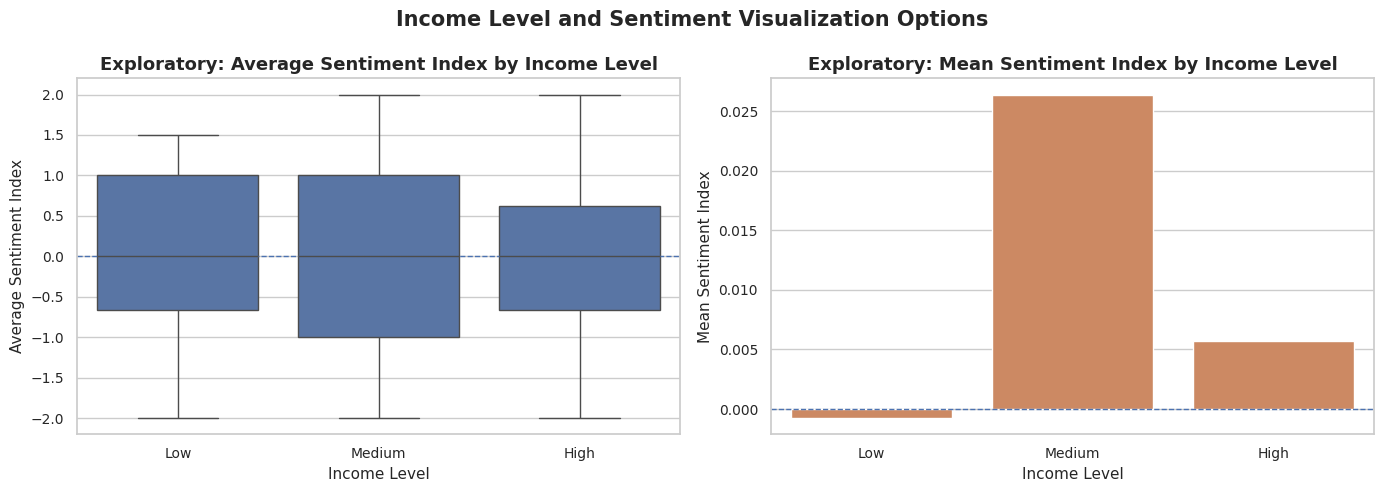

In [51]:
# @title Exploratory Average Sentiment Index by Income Level

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5)
)

sns.boxplot(
    data=demo_social,
    x="income_level",
    y="average_sentiment_index",
    order=income_order,
    ax=axes[0]
)

axes[0].axhline(
    0,
    linestyle="--",
    linewidth=1
)

axes[0].set_title(
    "Exploratory: Average Sentiment Index by Income Level"
)
axes[0].set_xlabel("Income Level")
axes[0].set_ylabel("Average Sentiment Index")


sns.barplot(
    data=income_sentiment_summary,
    x="income_level",
    y="mean_sentiment",
    order=income_order,
    color=secondary_color,
    ax=axes[1]
)

axes[1].axhline(
    0,
    linestyle="--",
    linewidth=1
)

axes[1].set_title(
    "Exploratory: Mean Sentiment Index by Income Level"
)
axes[1].set_xlabel("Income Level")
axes[1].set_ylabel("Mean Sentiment Index")

fig.suptitle(
    "Income Level and Sentiment Visualization Options",
    fontweight="bold"
)

plt.tight_layout()
plt.show()


#### Exploratory Review

The sentiment-index comparison is an optional exploratory diagnostic and depends on an ordinal numeric encoding.

**Visualization Decision:** **DROP FROM FINAL.** Milestone 2 uses categorical sentiment composition instead.


## 6. Transaction Behavior and Social Media Engagement

This section combines customer-level transaction metrics with customer-level social media engagement metrics.

Both source datasets contain multiple records for some customers. To prevent many-to-many duplication, transaction records and social media interactions are first summarized separately at the `customer_id` level before being merged.

The analysis explores whether customers with greater recorded social media engagement also show differences in spending or purchasing frequency.

### Exploration Questions

| Analytical Question | Variables | Candidate Visualization |
|---|---|---|
| Is social media engagement associated with total customer spending? | `interaction_count`, `total_spend` | Scatter Plot, Regression Plot |
| Is social media engagement associated with purchase frequency? | `interaction_count`, `transaction_count` | Scatter Plot, Regression Plot |
| Is social media engagement associated with average transaction value? | `interaction_count`, `average_transaction_amount` | Scatter Plot |


### 6.1 Prepare the Matched Transaction-Social Media Dataset

The customer-level transaction metrics from Section 4 and customer-level social media metrics from Section 3.7 are matched using `customer_id`.

This creates one row per matched customer and prevents many-to-many duplication between transaction events and social media interaction events.


In [52]:
# @title Merge Customer-Level Transaction and Social Media Metrics

transaction_social = customer_transactions.merge(
    customer_social,
    on="customer_id",
    how="inner"
)

print(
    f"Customers with transaction records: "
    f"{customer_transactions['customer_id'].nunique():,}"
)

print(
    f"Customers with social media interactions: "
    f"{customer_social['customer_id'].nunique():,}"
)

print(
    f"Matched customers: "
    f"{transaction_social['customer_id'].nunique():,}"
)

display(transaction_social.head())


Customers with transaction records: 1,642
Customers with social media interactions: 1,640
Matched customers: 902


,customer_id,total_spend,transaction_count,average_transaction_amount,interaction_count,average_sentiment_index
0,0009fdd2-ae63-45ca-8d5b-d0ea98381f7b,389.69,1,389.69,2,0.5
1,00c15eff-8bcf-4d12-a5d4-992e45e3309f,100.29,1,100.29,2,0.0
2,00d4fbfe-5ce0-4d87-a307-b15801d1373e,709.10,2,354.55,1,-1.0
3,010c57b4-d6aa-44ef-9e92-d00ce9bbc28b,233.42,1,233.42,2,0.0
4,01264132-b542-471e-ba65-038975091843,389.67,1,389.67,2,-0.5


#### Matched Population

Only customers appearing in both the cleaned transaction and social media datasets are included in this analysis.

The resulting dataset contains one row per matched customer. Transaction and interaction events are not directly joined, preventing duplicate combinations of individual events.

Results from this section therefore describe the matched transaction-social media customer subset rather than the complete population of either source dataset.


### 6.2 Social Media Engagement and Total Spending

Interaction count and total spending are both customer-level numerical variables.

A scatter plot is used to examine whether customers with more recorded social media interactions also tend to have higher or lower total recorded spending.

A Pearson correlation coefficient is calculated to support the visual assessment of the linear relationship.


In [53]:
# @title Engagement and Total Spending Correlation

engagement_spend_corr = np.corrcoef(
    transaction_social["interaction_count"],
    transaction_social["total_spend"]
)[0, 1]

print(
    f"Correlation between interaction count and total spending: "
    f"{engagement_spend_corr:.2f}"
)


Correlation between interaction count and total spending: 0.03


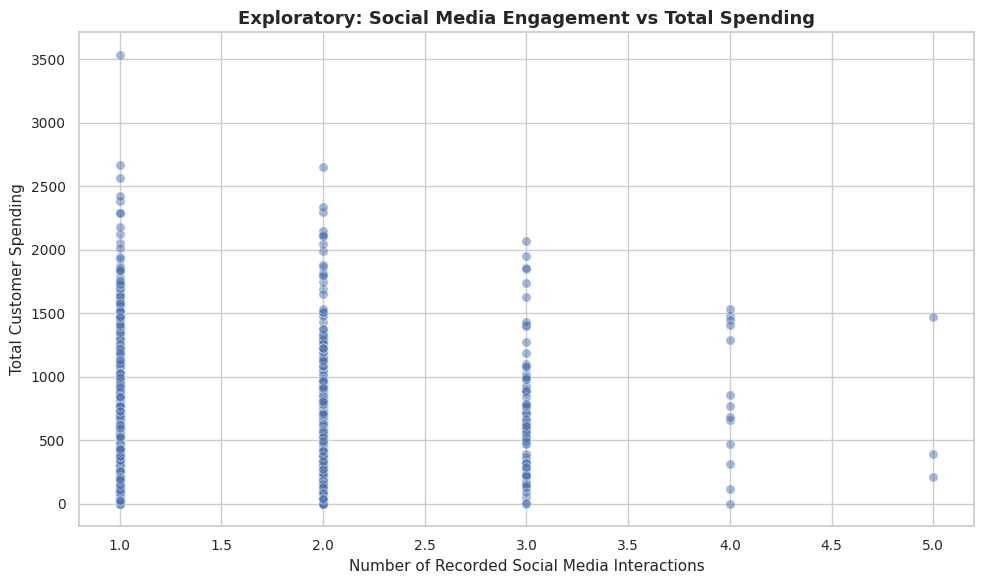

In [54]:
# @title Exploratory Engagement vs Total Spending

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=transaction_social,
    x="interaction_count",
    y="total_spend",
    alpha=0.5,
    s=45
)

plt.title(
    "Exploratory: Social Media Engagement vs Total Spending"
)
plt.xlabel("Number of Recorded Social Media Interactions")
plt.ylabel("Total Customer Spending")

plt.tight_layout()
plt.show()


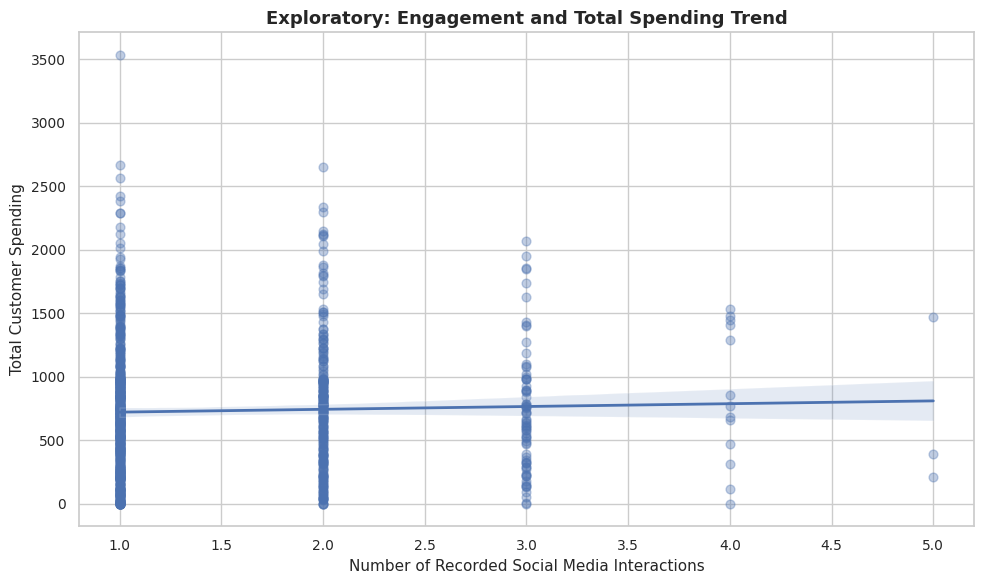

In [55]:
# @title Exploratory Engagement and Spending Trend

plt.figure(figsize=(10, 6))

sns.regplot(
    data=transaction_social,
    x="interaction_count",
    y="total_spend",
    scatter_kws={
        "alpha": 0.35,
        "s": 40
    },
    line_kws={
        "linewidth": 2
    }
)

plt.title(
    "Exploratory: Engagement and Total Spending Trend"
)
plt.xlabel("Number of Recorded Social Media Interactions")
plt.ylabel("Total Customer Spending")

plt.tight_layout()
plt.show()


#### Exploratory Review

The full-period engagement versus spending scatter shows little linear association.

A methodological refinement is required because the transaction dataset covers a longer period than the social-media dataset.

**Visualization Decision:** **REFINE.** Milestone 2 aligns both datasets to their common observation window before calculating customer-level engagement-purchasing relationships.


### 6.3 Social Media Engagement and Transaction Frequency

The number of recorded social media interactions is compared with the number of recorded transactions per customer.

This explores whether customers showing greater social media engagement also tend to make more recorded purchases.


In [56]:
# @title Engagement and Transaction Frequency Correlation

engagement_transaction_corr = np.corrcoef(
    transaction_social["interaction_count"],
    transaction_social["transaction_count"]
)[0, 1]

print(
    f"Correlation between interaction count and transaction count: "
    f"{engagement_transaction_corr:.2f}"
)


Correlation between interaction count and transaction count: 0.03


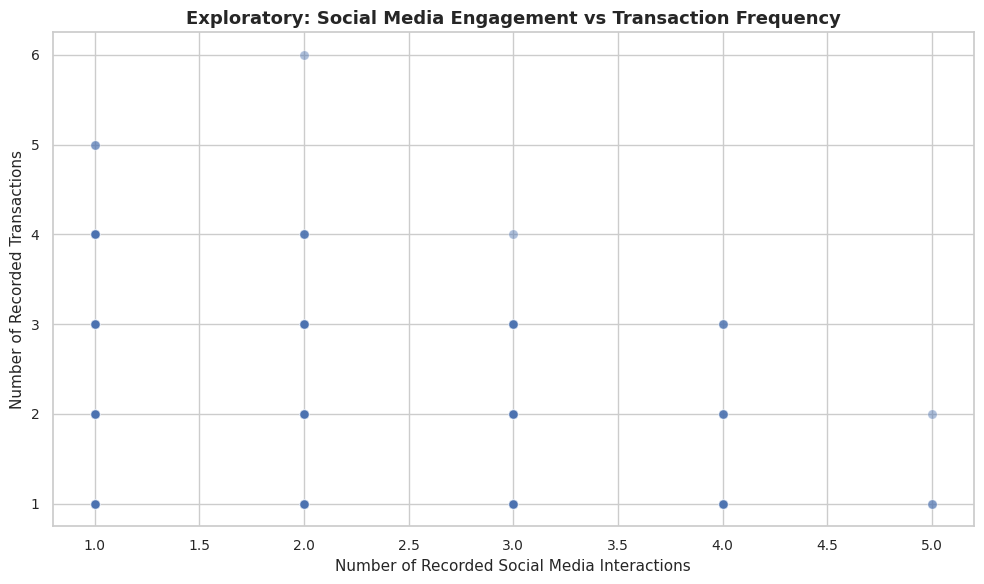

In [57]:
# @title Exploratory Engagement vs Transaction Frequency

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=transaction_social,
    x="interaction_count",
    y="transaction_count",
    alpha=0.45,
    s=45
)

plt.title(
    "Exploratory: Social Media Engagement vs Transaction Frequency"
)
plt.xlabel("Number of Recorded Social Media Interactions")
plt.ylabel("Number of Recorded Transactions")

plt.tight_layout()
plt.show()


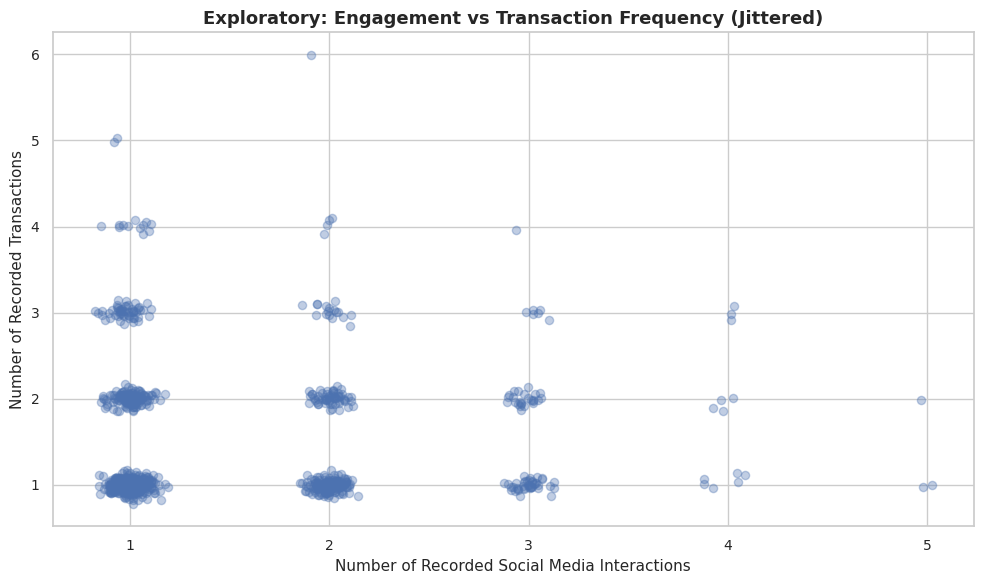

In [58]:
# @title Exploratory Engagement vs Transaction Frequency with Jitter

rng = np.random.default_rng(42)

jittered_interactions = (
    transaction_social["interaction_count"]
    + rng.normal(
        0,
        0.06,
        len(transaction_social)
    )
)

jittered_transactions = (
    transaction_social["transaction_count"]
    + rng.normal(
        0,
        0.06,
        len(transaction_social)
    )
)

plt.figure(figsize=(10, 6))

plt.scatter(
    jittered_interactions,
    jittered_transactions,
    alpha=0.35,
    s=35
)

plt.title(
    "Exploratory: Engagement vs Transaction Frequency (Jittered)"
)
plt.xlabel("Number of Recorded Social Media Interactions")
plt.ylabel("Number of Recorded Transactions")

plt.tight_layout()
plt.show()


#### Exploratory Review

The engagement versus transaction-count plot shows substantial overlap.

**Visualization Decision:** **DROP AS A STANDALONE FINAL CHART.** The relationship is retained numerically in the final correlation-summary dot plot.


### 6.4 Social Media Engagement and Average Transaction Amount

Total spending combines both transaction frequency and transaction value.

To examine purchasing value separately, interaction count is compared with each customer's average transaction amount.

This analysis explores whether customers with greater recorded social media engagement tend to have different typical transaction values.


In [59]:
# @title Engagement and Average Transaction Amount Correlation

engagement_avg_amount_corr = np.corrcoef(
    transaction_social["interaction_count"],
    transaction_social["average_transaction_amount"]
)[0, 1]

print(
    f"Correlation between interaction count and "
    f"average transaction amount: "
    f"{engagement_avg_amount_corr:.2f}"
)


Correlation between interaction count and average transaction amount: 0.01


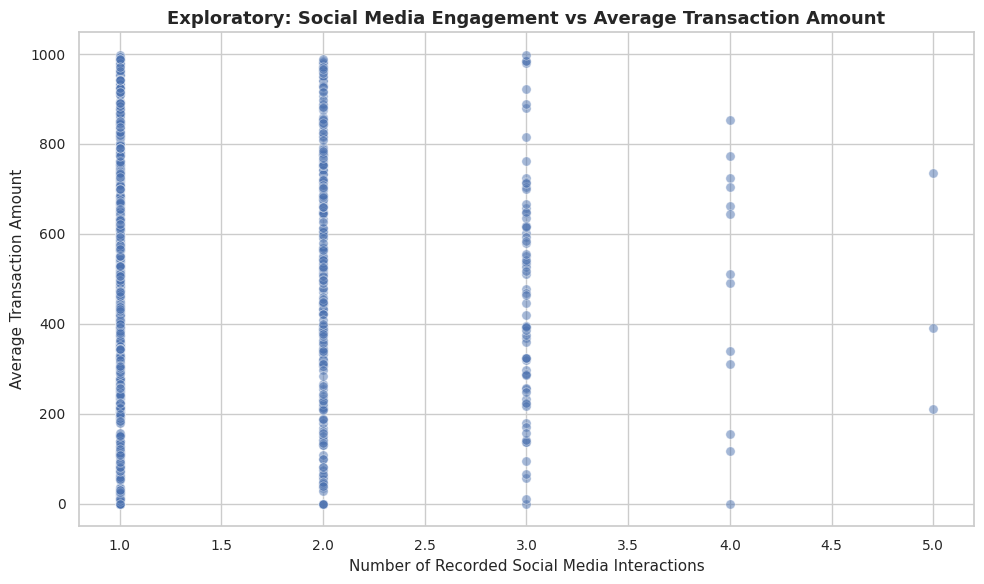

In [60]:
# @title Exploratory Engagement vs Average Transaction Amount

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=transaction_social,
    x="interaction_count",
    y="average_transaction_amount",
    alpha=0.5,
    s=45
)

plt.title(
    "Exploratory: Social Media Engagement vs Average Transaction Amount"
)
plt.xlabel("Number of Recorded Social Media Interactions")
plt.ylabel("Average Transaction Amount")

plt.tight_layout()
plt.show()


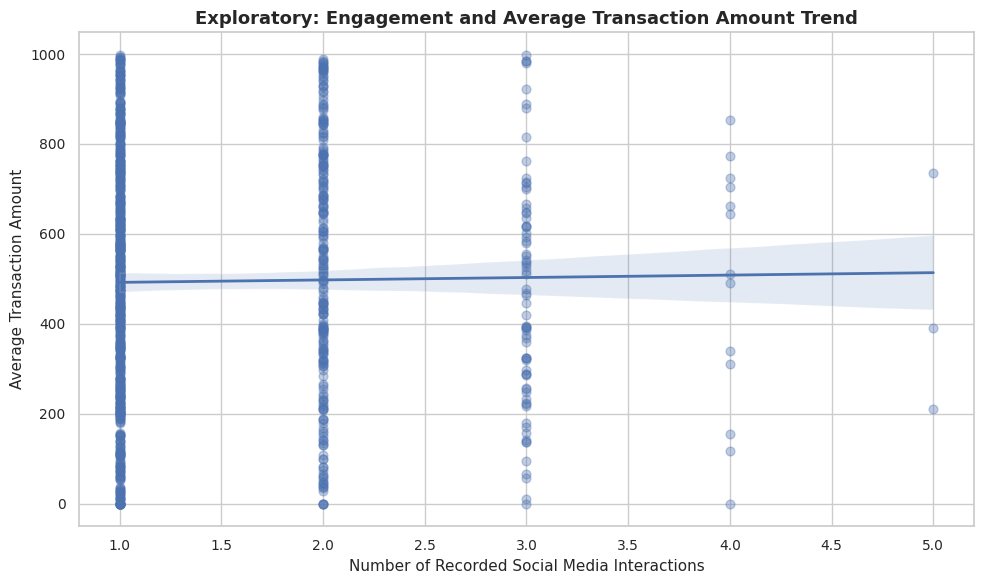

In [61]:
# @title Exploratory Engagement and Average Transaction Amount Trend

plt.figure(figsize=(10, 6))

sns.regplot(
    data=transaction_social,
    x="interaction_count",
    y="average_transaction_amount",
    scatter_kws={
        "alpha": 0.35,
        "s": 40
    },
    line_kws={
        "linewidth": 2
    }
)

plt.title(
    "Exploratory: Engagement and Average Transaction Amount Trend"
)
plt.xlabel("Number of Recorded Social Media Interactions")
plt.ylabel("Average Transaction Amount")

plt.tight_layout()
plt.show()


#### Exploratory Review

The engagement versus average-transaction-amount plot shows little visible linear structure.

**Visualization Decision:** **DROP AS A STANDALONE FINAL CHART.** The relationship is retained numerically in the final correlation-summary dot plot.


### 6.5 Engagement Relationship Summary

The three transaction-social media relationships are summarized numerically to support comparison between the exploratory scatter plots.


In [62]:
# @title Transaction and Social Media Correlation Summary

engagement_relationships = pd.DataFrame({
    "Relationship": [
        "Interaction Count vs Total Spending",
        "Interaction Count vs Transaction Count",
        "Interaction Count vs Average Transaction Amount"
    ],
    "Pearson Correlation": [
        engagement_spend_corr,
        engagement_transaction_corr,
        engagement_avg_amount_corr
    ]
})

engagement_relationships["Pearson Correlation"] = (
    engagement_relationships["Pearson Correlation"]
    .round(2)
)

display(engagement_relationships)


,Relationship,Pearson Correlation
0,Interaction Count vs Total Spending,0.03
1,Interaction Count vs Transaction Count,0.03
2,Interaction Count vs Average Transaction Amount,0.01


#### Exploratory Comparison

The three engagement-purchasing scatter plots all show weak linear relationships.

**Visualization Decision:** **REFINE.** Milestone 2 summarizes the three time-aligned Pearson correlations in one compact dot plot and retains only one supporting scatter plot for raw-data context.


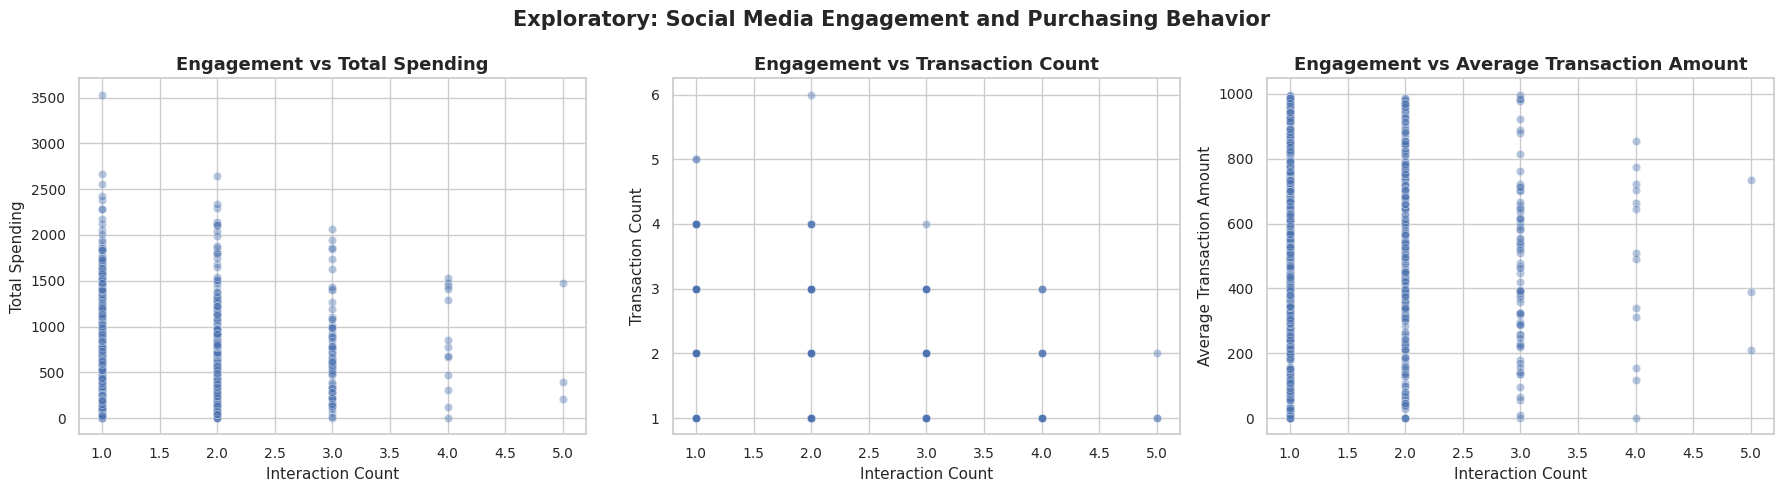

In [63]:
# @title Exploratory Engagement Relationship Comparison

fig, axes = plt.subplots(
    1,
    3,
    figsize=(18, 5)
)

sns.scatterplot(
    data=transaction_social,
    x="interaction_count",
    y="total_spend",
    alpha=0.4,
    ax=axes[0]
)

axes[0].set_title("Engagement vs Total Spending")
axes[0].set_xlabel("Interaction Count")
axes[0].set_ylabel("Total Spending")


sns.scatterplot(
    data=transaction_social,
    x="interaction_count",
    y="transaction_count",
    alpha=0.4,
    ax=axes[1]
)

axes[1].set_title("Engagement vs Transaction Count")
axes[1].set_xlabel("Interaction Count")
axes[1].set_ylabel("Transaction Count")


sns.scatterplot(
    data=transaction_social,
    x="interaction_count",
    y="average_transaction_amount",
    alpha=0.4,
    ax=axes[2]
)

axes[2].set_title("Engagement vs Average Transaction Amount")
axes[2].set_xlabel("Interaction Count")
axes[2].set_ylabel("Average Transaction Amount")

fig.suptitle(
    "Exploratory: Social Media Engagement and Purchasing Behavior",
    fontweight="bold"
)

plt.tight_layout()
plt.show()


### 6.6 Common Observation-Window Refinement

The exploratory transaction-social analysis above uses each dataset's full available period. Because transactions cover **July 2022 to June 2024** while social interactions cover **July 2023 to June 2024**, the final Milestone 2 relationship analysis should compare behavior over the shared period.

This refinement does not remove the earlier exploratory plots. It tests whether the relationship changes when both sources use the same observation window.


In [64]:
# @title Align Transaction and Social Observation Windows

transactions["transaction_date"] = pd.to_datetime(
    transactions["transaction_date"],
    errors="coerce"
)

social["interaction_date"] = pd.to_datetime(
    social["interaction_date"],
    errors="coerce"
)

common_start = max(
    transactions["transaction_date"].min(),
    social["interaction_date"].min()
)

common_end = min(
    transactions["transaction_date"].max(),
    social["interaction_date"].max()
)

transactions_common = transactions.loc[
    transactions["transaction_date"].between(
        common_start,
        common_end
    )
].copy()

customer_transactions_common = (
    transactions_common
    .groupby("customer_id", as_index=False)
    .agg(
        total_spend=("amount", "sum"),
        transaction_count=("transaction_id", "count"),
        average_transaction_amount=("amount", "mean")
    )
)

transaction_social_aligned = (
    customer_transactions_common
    .merge(
        customer_social,
        on="customer_id",
        how="inner"
    )
)

print(
    "Common observation window:",
    common_start.date(),
    "to",
    common_end.date()
)

print(
    "Matched customers:",
    f"{transaction_social_aligned['customer_id'].nunique():,}"
)


Common observation window: 2023-07-01 to 2024-06-30
Matched customers: 564


In [65]:
# @title Compare Time-Aligned Engagement Relationships

aligned_relationship_rows = []

for label, column in [
    ("Total Spending", "total_spend"),
    ("Transaction Count", "transaction_count"),
    ("Average Transaction Amount", "average_transaction_amount")
]:
    correlation, p_value = stats.pearsonr(
        transaction_social_aligned["interaction_count"],
        transaction_social_aligned[column]
    )

    aligned_relationship_rows.append({
        "Relationship": label,
        "Pearson Correlation": correlation,
        "p_value": p_value
    })

aligned_engagement_relationships = pd.DataFrame(
    aligned_relationship_rows
)

display(
    aligned_engagement_relationships.style.format({
        "Pearson Correlation": "{:.3f}",
        "p_value": "{:.4f}"
    })
)


,Relationship,Pearson Correlation,p_value
0,Total Spending,0.068,0.1075
1,Transaction Count,0.055,0.1949
2,Average Transaction Amount,0.035,0.4011


#### Refinement Review

After aligning both datasets to the same July 2023 to June 2024 period, the engagement-purchasing correlations remain weak.

**Visualization Decision:** Carry the aligned relationship summary into Milestone 2. The final notebook should not use raw interaction count as a strong proxy for customer purchasing value.


### 6.7 Gender and Product-Category Participation Experiment

The simple gender count plot does not answer whether purchasing behavior differs by recorded gender.

A more useful customer-level question is:

**Is recorded gender associated with whether a customer purchased from each product category at least once?**

Each category is converted into a customer-level purchased / not-purchased variable. A separate Chi-square test is performed for each category, followed by Bonferroni correction and Cramer's V effect-size calculation.


In [66]:
# @title Test Gender and Product-Category Participation

demographic_transaction_customers = (
    demographics[
        ["customer_id", "gender"]
    ]
    .merge(
        transactions[
            ["customer_id"]
        ].drop_duplicates(),
        on="customer_id",
        how="inner"
    )
)

category_test_rows = []

for category in sorted(
    transactions["product_category"].dropna().unique()
):
    category_customers = set(
        transactions.loc[
            transactions["product_category"].eq(category),
            "customer_id"
        ]
    )

    category_test = (
        demographic_transaction_customers
        .copy()
    )

    category_test["purchased"] = (
        category_test["customer_id"]
        .isin(category_customers)
    )

    contingency = pd.crosstab(
        category_test["gender"],
        category_test["purchased"]
    )

    chi2, p_value, dof, expected = (
        stats.chi2_contingency(contingency)
    )

    n = contingency.to_numpy().sum()

    cramers_v = np.sqrt(
        chi2
        / (
            n
            * min(
                contingency.shape[0] - 1,
                contingency.shape[1] - 1
            )
        )
    )

    rates = (
        category_test
        .groupby("gender", observed=False)["purchased"]
        .mean()
        .mul(100)
    )

    category_test_rows.append({
        "Product Category": category,
        "Female Participation %": rates.get(
            "Female",
            np.nan
        ),
        "Male Participation %": rates.get(
            "Male",
            np.nan
        ),
        "Raw p-value": p_value,
        "Cramer's V": cramers_v
    })

gender_category_results = pd.DataFrame(
    category_test_rows
)

gender_category_results["Bonferroni p-value"] = np.minimum(
    gender_category_results["Raw p-value"]
    * len(gender_category_results),
    1.0
)

display(
    gender_category_results.style.format({
        "Female Participation %": "{:.2f}",
        "Male Participation %": "{:.2f}",
        "Raw p-value": "{:.4f}",
        "Bonferroni p-value": "{:.4f}",
        "Cramer's V": "{:.3f}"
    })
)


,Product Category,Female Participation %,Male Participation %,Raw p-value,Cramer's V,Bonferroni p-value
0,Automotive,28.28,25.83,0.3490,0.026,1.0000
1,Clothing,27.34,28.98,0.5517,0.016,1.0000
2,Electronics,26.88,28.83,0.4681,0.020,1.0000
3,Health & Beauty,25.00,27.48,0.3400,0.026,1.0000
4,Home & Garden,30.16,23.42,0.0072,0.074,0.0361


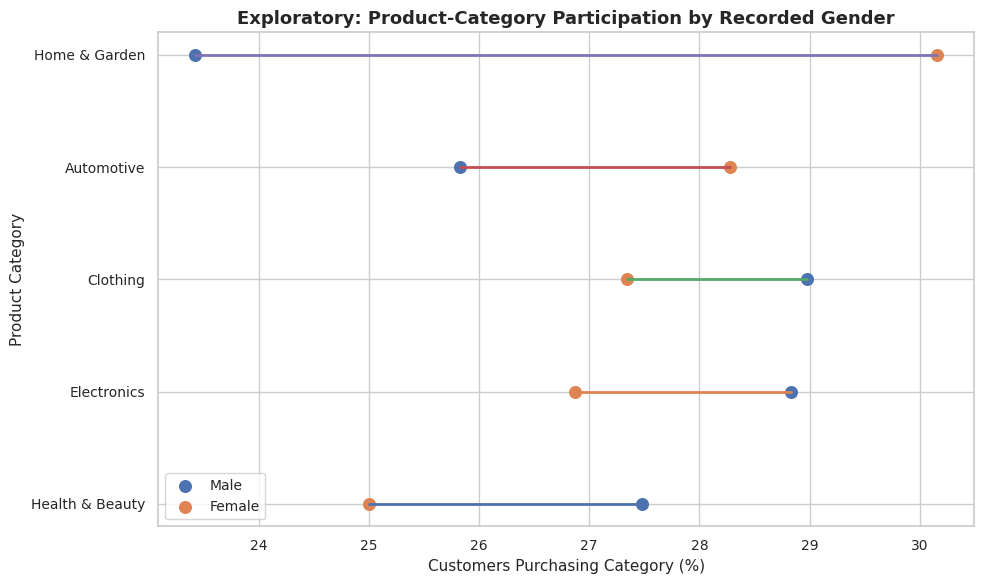

In [67]:
# @title Exploratory Gender Participation Dumbbell Chart

gender_plot = (
    gender_category_results
    .assign(
        difference=lambda df:
        df["Female Participation %"]
        - df["Male Participation %"]
    )
    .sort_values("difference")
    .reset_index(drop=True)
)

y_positions = np.arange(
    len(gender_plot)
)

fig, ax = plt.subplots(
    figsize=(10, 6)
)

for y, row in gender_plot.iterrows():
    ax.plot(
        [
            row["Male Participation %"],
            row["Female Participation %"]
        ],
        [y, y],
        linewidth=2
    )

ax.scatter(
    gender_plot["Male Participation %"],
    y_positions,
    label="Male",
    s=70
)

ax.scatter(
    gender_plot["Female Participation %"],
    y_positions,
    label="Female",
    s=70
)

ax.set_yticks(y_positions)
ax.set_yticklabels(
    gender_plot["Product Category"]
)

ax.set_xlabel(
    "Customers Purchasing Category (%)"
)

ax.set_ylabel("Product Category")

ax.set_title(
    "Exploratory: Product-Category Participation by Recorded Gender"
)

ax.legend()

plt.tight_layout()
plt.show()


#### Exploratory Review

Home & Garden shows the largest recorded gender participation gap. After Bonferroni correction, it remains statistically detectable, but Cramer's V is very small.

**Visualization Decision:** **ADD / KEEP FOR MILESTONE 2.** The dumbbell chart directly communicates paired participation rates while the statistical test prevents a small difference from being overstated. Gender should remain a diagnostic variable rather than a broad targeting rule.


# Part III: Integrated Exploration and Visualization Evaluation

The final exploratory phase combines selected customer-level variables from all three FinMark datasets.

The purpose is not to create every possible visualization. Instead, this section evaluates whether broader customer-level relationships become visible when demographic characteristics, purchasing behavior, and social media engagement are considered together.

Only customers represented across all three cleaned datasets are included in the integrated analysis.

## 7. Integrated Customer-Level Exploration

The demographics dataset already represents individual customers, while the transaction and social media datasets contain multiple event records per customer.

Before integration:

- transaction records are summarized into customer-level purchasing metrics;
- social media records are summarized into customer-level engagement metrics; and
- both summaries are merged with the demographics dataset using `customer_id`.

This creates one analytical row per matched customer and avoids many-to-many event duplication.

In [68]:
# @title Prepare Integrated Customer-Level Dataset

integrated_customers = (
    demographics
    .merge(
        customer_transactions,
        on="customer_id",
        how="inner"
    )
    .merge(
        customer_social,
        on="customer_id",
        how="inner"
    )
)

print(
    f"Demographic customers: "
    f"{demographics['customer_id'].nunique():,}"
)

print(
    f"Customers with transaction records: "
    f"{customer_transactions['customer_id'].nunique():,}"
)

print(
    f"Customers with social media interactions: "
    f"{customer_social['customer_id'].nunique():,}"
)

print(
    f"Customers matched across all three datasets: "
    f"{integrated_customers['customer_id'].nunique():,}"
)

print(
    f"Duplicate customer rows after integration: "
    f"{integrated_customers['customer_id'].duplicated().sum():,}"
)

display(integrated_customers.head())

Demographic customers: 2,378
Customers with transaction records: 1,642
Customers with social media interactions: 1,640
Customers matched across all three datasets: 718
Duplicate customer rows after integration: 0


,customer_id,age,gender,location,income_level,signup_date,total_spend,transaction_count,average_transaction_amount,interaction_count,average_sentiment_index
0,9207fa75-5758-48d1-94ad-19c041e0520f,51,Female,Jensenberg,Low,2022-11-17,660.87,1,660.870000,2,0.0
1,7d1f2bbc-8d16-4fbc-9b37-ece3324e8ed4,50,Female,Jessebury,High,2023-08-24,733.46,1,733.460000,2,0.0
2,2de49c7c-32ae-4ba8-b058-622a090d7094,53,Female,Emilyville,Low,2022-02-13,891.74,3,297.246667,3,1.0
3,8602d631-457c-49c1-8b59-8efb2a4448d4,51,Male,East Keithville,High,2022-04-17,815.21,1,815.210000,2,0.5
4,b2f4c25e-be11-4912-9d14-5c288616e56e,29,Male,South Timothyhaven,High,2023-07-09,533.94,1,533.940000,1,1.0


### Integrated Matched Population

The integrated dataset contains only customers whose `customer_id` is present in the demographics, transaction, and social media datasets.

Each matched customer appears once after customer-level aggregation.

Because this is a matched subset, findings from this section should not automatically be generalized to every record in the original FinMark datasets.

### 7.2 Integrated Numerical Features

The integrated exploratory analysis focuses on numerical variables that represent different aspects of customer behavior.

| Feature | Meaning |
|---|---|
| `age` | Customer age in years |
| `total_spend` | Total recorded transaction amount per customer |
| `transaction_count` | Number of recorded transactions per customer |
| `average_transaction_amount` | Average transaction amount per customer |
| `interaction_count` | Number of recorded social media interactions per customer |

The customer identifier is excluded because it is an identifier rather than a numerical feature.

The exploratory sentiment index is also excluded from the primary Pearson correlation matrix because it originates from ordered categorical sentiment labels rather than a true continuous measurement scale.

### 7.3 Integrated Customer-Level Correlation Analysis

A Pearson correlation matrix is used to compare the linear relationships among selected customer-level numerical variables.

The heatmap provides a compact overview of which variables move together and which show little linear association.

Correlation values range from `-1` to `1`:

- values closer to `1` indicate stronger positive linear association;
- values closer to `-1` indicate stronger negative linear association; and
- values closer to `0` indicate weaker linear association.

Correlation describes association and does not establish causation.

In [69]:
# @title Integrated Customer-Level Correlation Matrix

integrated_features = [
    "age",
    "total_spend",
    "transaction_count",
    "average_transaction_amount",
    "interaction_count"
]

integrated_corr = (
    integrated_customers[integrated_features]
    .corr(method="pearson")
)

display(
    integrated_corr.style.format("{:.2f}")
)

,age,total_spend,transaction_count,average_transaction_amount,interaction_count
age,1.00,0.01,-0.05,0.07,0.07
total_spend,0.01,1.00,0.70,0.63,0.07
transaction_count,-0.05,0.70,1.00,-0.03,0.07
average_transaction_amount,0.07,0.63,-0.03,1.00,0.04
interaction_count,0.07,0.07,0.07,0.04,1.00


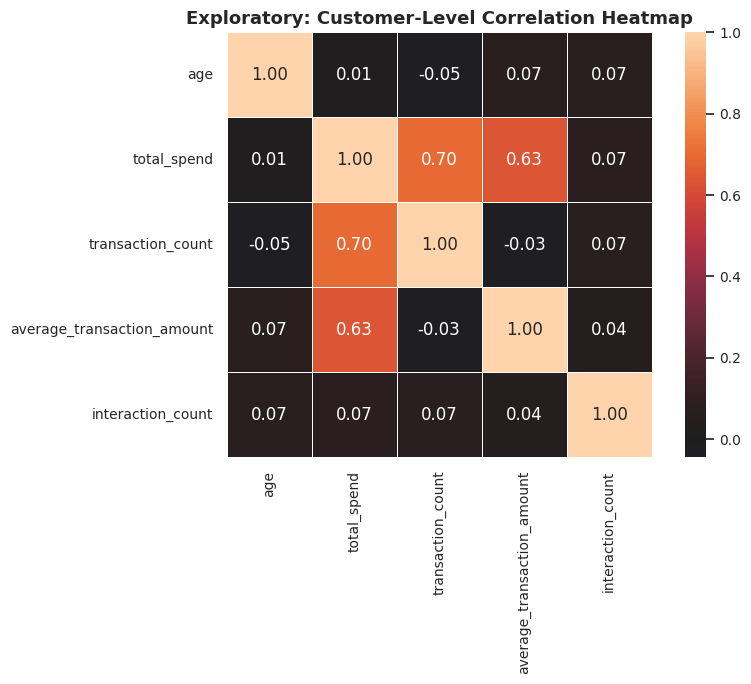

In [70]:
# @title Exploratory Integrated Correlation Heatmap

plt.figure(figsize=(9, 7))

sns.heatmap(
    integrated_corr,
    annot=True,
    fmt=".2f",
    center=0,
    square=True,
    linewidths=0.5
)

plt.title(
    "Exploratory: Customer-Level Correlation Heatmap"
)

plt.tight_layout()
plt.show()

#### Exploratory Review

The heatmap is useful for broad EDA, but its strongest correlations are largely expected from mathematically related purchasing measures such as total spending, transaction count, and average transaction amount.

**Visualization Decision:** **EDA ONLY / DROP FROM MAIN MILESTONE 2 VIEW.** It may remain as supporting exploratory evidence but should not be presented as a headline business finding.


### 7.4 Integrated Pair Plot Experiment

A Seaborn pair plot is tested to examine several numerical relationships simultaneously.

The experiment uses customer age, total spending, transaction frequency, and social media interaction frequency. Income level is used as a grouping variable to determine whether broad demographic grouping reveals visible separation or clustering.

The pair plot is exploratory. Because pair plots can become visually dense, it will only be considered for Milestone 2 if it provides information that is clearer than the individual charts.

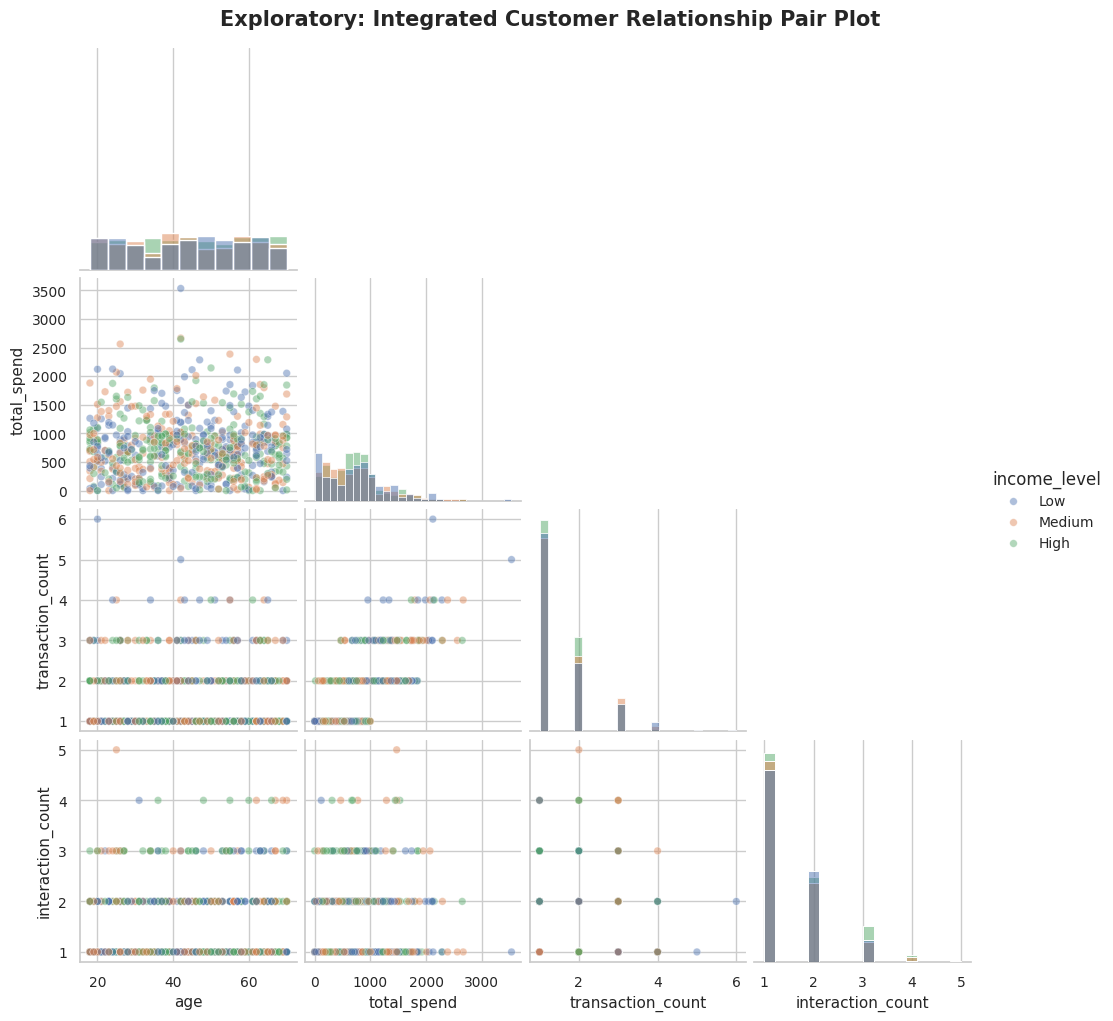

In [71]:
# @title Exploratory Integrated Customer Pair Plot

pairplot_features = [
    "age",
    "total_spend",
    "transaction_count",
    "interaction_count",
    "income_level"
]

sns.pairplot(
    integrated_customers[pairplot_features],
    vars=[
        "age",
        "total_spend",
        "transaction_count",
        "interaction_count"
    ],
    hue="income_level",
    hue_order=["Low", "Medium", "High"],
    diag_kind="hist",
    corner=True,
    plot_kws={
        "alpha": 0.45,
        "s": 30
    }
)

plt.suptitle(
    "Exploratory: Integrated Customer Relationship Pair Plot",
    y=1.02,
    fontweight="bold"
)

plt.show()

#### Exploratory Review

The pair plot repeats relationships that are clearer in simpler individual charts and becomes visually dense.

**Visualization Decision:** **DROP FROM FINAL.** Retain only as an exploratory experiment.


## 8. Visualization Candidate Evaluation

The exploratory visualizations are reviewed before selecting charts for Milestone 2.

Each visualization is evaluated using the following criteria:

1. **Analytical relevance**: Does the visualization answer a meaningful FinMark question?
2. **Variable suitability**: Is the chart appropriate for the type of data being displayed?
3. **Readability**: Can the pattern be understood without unnecessary complexity?
4. **Analytical value**: Does the chart reveal information beyond a simple numerical table?
5. **Redundancy**: Does another visualization communicate the same information more effectively?
6. **Milestone 2 suitability**: Is the visualization useful enough to support formal interpretation?

Candidate decisions are classified as:

- **KEEP**: strong candidate for Milestone 2;
- **REFINE**: useful but requires formatting, aggregation, or presentation changes; or
- **DROP**: tested during Week 7 but does not provide enough analytical value for the final analysis.

### Candidate Review Table

| Analytical Area | Visualization Candidate | Decision | Reason |
|---|---|---|---|
| Customer age | Histogram | SUPPORTING | Useful descriptive context, not a core final finding |
| Customer age | Box Plot | DROP | Adds little beyond summary statistics |
| Customer composition | Gender Count Plot | DROP | Balanced categories; purchasing participation is more informative |
| Customer composition | Income Count Plot | DROP | Descriptive only |
| Customer signup | Monthly Signup Line | DROP FROM FINAL | Signup-date inconsistency limits lifecycle interpretation |
| Transaction amount | Histogram | KEEP | Clearly shows transaction-value spread |
| Transaction amount | Box Plot | DROP | Redundant with histogram and numerical summary |
| Product behavior | Product Category Bar | REFINE | Use count and total transaction value as small multiples |
| Product value | Category × Amount Box Plot | DROP | Strong overlap between categories |
| Payment behavior | Payment Method × Amount | DROP | Weak differentiation |
| Transaction activity | Monthly Line Plot | KEEP / REFINE | Use monthly count and total value separately |
| Social activity | Platform Count Plot | DROP | Balanced and mainly descriptive |
| Social sentiment | Sentiment Count Plot | REFINE | Use monthly sentiment composition instead |
| Platform sentiment | 100% Stacked Bar | DROP | Limited platform differentiation |
| Sentiment experiment | Sentiment Scatter Plot | DROP | Visually dense and relies on ordinal encoding |
| Demographics × Transactions | Income × Total Spend | DROP | Strong overlap |
| Demographics × Transactions | Age × Total Spend | DROP | Near-zero linear relationship |
| Demographics × Social | Income × Engagement | DROP | Weak differentiation |
| Transactions × Social | Engagement × Total Spend | REFINE | Align observation periods and retain one supporting scatter |
| Transactions × Social | Engagement × Transaction Count | DROP AS STANDALONE | Retain in compact relationship summary |
| Transactions × Social | Engagement × Average Amount | DROP AS STANDALONE | Retain in compact relationship summary |
| Transactions × Social | Correlation Dot Plot | ADD / KEEP | Compactly summarizes three weak aligned relationships |
| Gender × Product | Participation Dumbbell | ADD / KEEP | Directly compares paired participation rates |
| Social trend | Monthly Sentiment Composition | ADD / KEEP | Shows market sentiment changes over time |
| Integrated | Correlation Heatmap | EDA ONLY | Expected constructed-metric correlations dominate |
| Integrated | Pair Plot | DROP | Dense and redundant |


## 9. Milestone 1 Cross-Check

Week 7 visual exploration supports the Milestone 1 descriptive findings while also helping determine which relationships deserve final visualization.

Key cross-checks:

- customer age is broadly distributed, but age has almost no linear relationship with total spending;
- gender and income frequencies are broadly balanced, so simple count charts add little final decision value;
- product-category frequencies are relatively balanced, so category performance should use both count and transaction value;
- transaction amounts have a broad spread, supporting a final histogram;
- extreme sentiment categories are rare, supporting a simplified three-level sentiment composition for comparison;
- engagement-purchasing relationships remain weak after time-window alignment; and
- integrated heatmaps and pair plots are useful for EDA but are not clearer than the focused final charts.


| Milestone 1 Finding | Week 7 Visual Check | Assessment |
|---|---|---|
| Customer age was broadly distributed with no IQR-based potential outliers | Age Histogram and Box Plot | To be reviewed |
| Gender representation was evenly balanced | Gender Count Plot | To be reviewed |
| Income-level frequencies were relatively balanced | Income Count Plot | To be reviewed |
| Product-category frequencies were relatively balanced | Product Category Bar Chart | To be reviewed |
| Payment-method frequencies were relatively balanced | Payment Method Bar Chart | To be reviewed |
| Transaction amount had broad numerical spread without IQR-based potential outliers | Amount Histogram and Box Plot | To be reviewed |
| Extreme sentiment categories were rare | Sentiment Distribution | To be reviewed |
| Customer age showed almost no linear relationship with total spending | Age × Total Spend Scatter | To be reviewed |
| Engagement showed only a weak linear relationship with purchasing measures | Engagement Scatter Plots | To be reviewed |

## 10. Milestone 2 Candidate Selection

The Week 7 worksheet remains the broad exploratory record. Milestone 2 will use a smaller set of visualizations that directly addresses FinMark's problem statement.

The final selection is organized around two analytical goals:

1. **Market trends:** monthly transaction activity, product-category performance, transaction-value distribution, and monthly sentiment composition.
2. **Customer behavior:** gender-category participation and time-aligned social engagement versus purchasing behavior.

Visualizations that are descriptive but weak, redundant, methodologically limited, or difficult to interpret are retained only in Week 7 as evidence of the exploratory process.


### Selection Status

#### KEEP
- Monthly transaction activity
- Transaction amount histogram
- Gender × product-category participation dumbbell
- Monthly sentiment composition

#### REFINE
- Product-category bar chart -> transaction count + total transaction value small multiples
- Engagement-purchasing scatter set -> time-aligned correlation dot plot + one supporting scatter

#### EDA ONLY / DROP FROM FINAL
- age and income segmentation charts
- payment-method comparisons
- platform and interaction-type frequency charts
- platform-by-sentiment and interaction-type-by-sentiment charts
- ordinal sentiment scatter experiments
- full integrated correlation heatmap
- integrated pair plot
- signup-derived lifecycle analysis until date inconsistency is resolved


## 11. Week 7 Key Findings

**Finding 1 -> Evidence -> Interpretation -> FinMark Relevance**

Monthly transaction activity fluctuates across the observation period. The final milestone should retain the time-series view because it provides a direct market-activity baseline, while avoiding unsupported claims about seasonality.

**Finding 2 -> Evidence -> Interpretation -> FinMark Relevance**

Product categories are relatively balanced. A simple category count is not enough for the final analysis, so product performance should combine transaction count with total transaction value.

**Finding 3 -> Evidence -> Interpretation -> FinMark Relevance**

Individual transaction amounts have a broad numerical spread. The transaction histogram remains useful because it communicates customer purchase-value variation clearly.

**Finding 4 -> Evidence -> Interpretation -> FinMark Relevance**

Most demographic and income relationship experiments show weak separation. These tests remain valuable because they prevent unsupported segmentation claims.

**Finding 5 -> Evidence -> Interpretation -> FinMark Relevance**

Home & Garden shows a statistically detectable gender participation difference after Bonferroni correction, but the effect size is very small. Gender should therefore be treated as a diagnostic rather than a strong targeting rule.

**Finding 6 -> Evidence -> Interpretation -> FinMark Relevance**

Social engagement and purchasing measures remain weakly related after aligning transaction and social-media observation periods. Raw interaction frequency should not be used as a standalone proxy for customer value.

**Finding 7 -> Evidence -> Interpretation -> FinMark Relevance**

Social sentiment composition varies month to month. The final milestone should use monthly sentiment composition rather than platform frequency as the primary social-media market view.


## 12. Limitations

The Week 7 exploratory analysis has several important limitations:

- The three FinMark datasets do not contain exactly the same customer population.
- Cross-dataset analyses therefore use matched subsets rather than every original record.
- Transaction and social media datasets cover different observation periods, so final cross-channel comparisons require a common time window.
- Customer-level aggregation simplifies event data and may hide variation between individual transactions or interactions.
- Recorded signup dates are inconsistent with some transaction dates, limiting tenure or post-signup lifecycle analysis.
- The location field is not standardized into reliable geographic units, so geospatial visualization is not used.
- Pearson correlation measures linear association and may not capture nonlinear relationships.
- Correlation does not establish causation.
- The experimental sentiment index represents ordered categories and should not be interpreted as a true continuous measurement scale.
- Histogram appearance can change depending on the selected number of bins.
- Jitter used in selected scatter plots changes only visual position and not the underlying data.
- Statistical significance should be interpreted together with effect size and business relevance.
- Exploratory visualizations are intended to identify useful analytical directions and are not predictive models.


## 13. Week 7 Completion Check

The revised exploratory worksheet confirms that:

- [x] Final cleaned FinMark datasets are used.
- [x] Dataset structure and quality are revalidated.
- [x] Pandas and NumPy are used for preparation and numerical analysis.
- [x] Matplotlib and Seaborn are used for visualization exploration.
- [x] Numerical distributions are explored.
- [x] Categorical frequencies and imbalance are explored.
- [x] Time-based trends are explored.
- [x] Variable relationships are explored.
- [x] Meaningful cross-dataset combinations are explored at the customer level.
- [x] Event-level datasets are aggregated before cross-dataset relationship analysis.
- [x] Transaction-social observation windows are explicitly aligned for the final relationship test.
- [x] Visualization candidates are classified as KEEP, REFINE, EDA ONLY, or DROP.
- [x] Findings are cross-checked against Milestone 1.
- [x] Final Milestone 2 visualization candidates are identified.
- [x] Interpretations distinguish association from causation.
